In [1]:
# Cell 0: choose where everything is stored (data, caches, outputs all live under ROOT)
import os, sys
from pathlib import Path
USE_DRIVE = True                   # True: Google Drive (survives disconnects). False: local folder (Colab: /content, lost on disconnect)
DRIVE_DIR = "conformal_budget_miracl"     # created automatically under MyDrive; no manual step needed
IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content/sample_data")
if IN_COLAB and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive"); ROOT = Path("/content/drive/MyDrive") / DRIVE_DIR
    except Exception as e:
        print("Drive mount failed, using /content instead (files will be lost on disconnect):", e); ROOT = Path("/content/conformal_budget")
elif IN_COLAB: ROOT = Path("/content/conformal_budget")
else: ROOT = Path.cwd()
ROOT.mkdir(parents=True, exist_ok=True); os.chdir(ROOT)
print("ROOT =", ROOT, "| Colab:", IN_COLAB, "| Drive:", USE_DRIVE and IN_COLAB)

Drive mount failed, using /content instead (files will be lost on disconnect): Error: credential propagation was unsuccessful
ROOT = /content/conformal_budget | Colab: True | Drive: True


# Conformal Token Budgets for Cross-Lingual Retrieval-Augmented Generation

**Does a context-token budget calibrated with split conformal prediction on English keep its coverage guarantee on Hindi?**

Authors: *[author names]* &nbsp;|&nbsp; Institution: *[department, university]* &nbsp;|&nbsp; Supervisor: *[name]* &nbsp;|&nbsp; Date: *[date]*

**Abstract.** *[To be written after the final run. Suggested content: the question; data (mMARCO English and Hindi, parallel passage identifiers); method (split conformal calibration of a token budget on the depth of the first relevant passage); the main numbers from the "Auto-drafted discussion" cell; the gate verdict; one sentence on limitations.]*

## 1. Problem and hypothesis

A retrieval-augmented generation system sends the top-ranked passages to a language model under a context budget measured in **tokens**. For a query $q$ let $d_1,\dots,d_K$ be the retrieved passages in rank order ($K=K_{\mathrm{RET}}$), let $\ell_j$ be the length of $d_j$ in tokens of a given tokenizer, and let $r^*(q)=\min\{j\le K : d_j \text{ is relevant}\}$. The **token depth** is

$$T(q)=\sum_{j=1}^{r^*(q)} (\ell_j + 4), \qquad T(q)=\infty \text{ if no relevant passage is in the top } K,$$

where 4 tokens are added per passage as formatting overhead. A budget $B$ *covers* $q$ if $T(q)\le B$, that is, if the first relevant passage fits inside the budget.

**Split conformal budget.** Given $n$ calibration items with depths $T_1,\dots,T_n$ and a miscoverage level $\alpha$, set $k=\lceil (n+1)(1-\alpha)\rceil$ and

$$B=T_{(k)} \quad (\text{the } k\text{-th smallest depth}), \qquad B=\infty \text{ if } k>n.$$

If calibration and test items are exchangeable, then $1-\alpha \le \Pr(T_{n+1}\le B) \le 1-\alpha + \tfrac{1}{n+1}$ (the upper bound holds when there are no ties).

**Hypothesis.** The guarantee requires exchangeability. English and Hindi depths are not exchangeable, because the same passage costs more tokens in Hindi and because retrieval quality may differ. We test whether an English-calibrated budget keeps $1-\alpha$ coverage on Hindi. There are three consequences:

1. **Infeasibility.** If more than a fraction $\alpha$ of items have $T=\infty$, then $B=\infty$: the problem is limited by retrieval, not by the budget.
2. **Under-coverage under shift.** The coverage of the English budget on Hindi is $F_{HI}(F_{EN}^{-1}(1-\alpha))$ up to finite-sample error, and $|\Pr_{HI}(T\le B)-\Pr_{EN}(T\le B)|\le \sup_x|F_{EN}(x)-F_{HI}(x)|$ (the Kolmogorov–Smirnov distance), so the gap is bounded by how different the two depth distributions are.
3. **Token price of translation.** If Hindi depths are about $\kappa$ times English depths, a Hindi-calibrated budget should satisfy $B_{HI}/B_{EN}\approx\kappa$, where $\kappa$ is the measured Hindi/English token ratio of the tokenizer.

The pre-committed decision rule (the *gate*, Section 6) is fixed before any result is seen: $\text{GAP\_MIN}=0.05$ and $\text{NEAR}=0.02$. The gap is defined as $(1-\alpha)-\text{coverage}$, so a positive gap means under-coverage.

In [2]:
# Constants (fixed before any result is seen). Do not tune on test results.
QUICK = False                      # True: 200-query smoke test; False: full run
N_QUICK, N_FULL = 200, 3000        # N_FULL may be raised up to 6980
N_CPU_CAP = 40                     # only used for a QUICK smoke test without GPU
MAX_HOURS = 2.0                    # embedding time budget; N is reduced if the ETA exceeds it
SEED = 0
SEEDS = (SEED, SEED + 1, SEED + 2) # SEED is the pre-committed one; the others are robustness
K_RET, POOL_BM25, MAXLEN = 30, 100, 256
OVERHEAD = 4                       # passage cost = tokens + 4
R = 200                            # repeated group splits
ALPHAS = (0.05, 0.1, 0.2)
KS_FEW = (10, 25, 50, 100, 200)
TOPK_BASE = (1, 3, 5, 10)
FIXED_BUDGETS = (256, 512, 1024, 2048)
GAP_MIN, NEAR = 0.05, 0.02         # gate thresholds (pre-committed)
GATE_ALPHA = 0.1
N_BOOT, SPLITS_PER_BOOT = 500, 10
TOKS = ("cl100k", "o200k", "qwen3", "bge-m3")

INCLUDE_REL_IN_POOL = True         # True: pool = BM25 top-100 + relevant pids (optimistic); False: BM25 top-100 only
RUN_NOREL_ROBUSTNESS = True        # also run the other pool setting and compare
USE_RERANKER = False               # True: rerank top RERANK_TOP dense candidates with bge-reranker-v2-m3
RERANK_TOP, RERANK_MODEL = 50, "BAAI/bge-reranker-v2-m3"
EXTRA_LANGS = ()                   # e.g. ("russian",) or ("arabic",): extra test language for conditions b-d
SYNTHETIC_TEST = False             # offline pipeline test on fake data (never for the real run)
RUN_MLQA = False                   # optional last-but-one cell
MIN_FREE_GB = 4                   # stop if less space is free at ROOT; real need is ~2-3 GB, lower this (e.g. 5) if your Drive is nearly full

LANGS = ("english", "hindi") + tuple(EXTRA_LANGS)
TEST_LANGS = LANGS[1:]

In [3]:
import sys, subprocess, importlib, time, math, json, gzip, tarfile, io, re, random, warnings, zipfile, pickle, zlib, shutil
import torch
CUDA = torch.cuda.is_available(); DEV = "cuda" if CUDA else "cpu"
assert CUDA or QUICK or SYNTHETIC_TEST, ("No CUDA GPU found. In Colab choose Runtime > Change runtime type > T4 GPU, "
                                         "then run again (QUICK=False requires a GPU).")
def _need(mod):
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", mod])
from importlib import metadata as _md
def _ver(p):
    try: return tuple(int(x) for x in re.findall(r"\d+", _md.version(p))[:2])
    except Exception: return None
if _ver("torch") and _ver("transformers") and _ver("torch") < (2, 6) and _ver("transformers") >= (5, 0):
    print("transformers>=5 needs torch>=2.6; installing transformers<5 (restart the kernel if transformers was already imported)")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.45,<5"])
for m in ("numpy", "pandas", "pyarrow", "requests", "tqdm", "scipy", "matplotlib", "huggingface_hub", "transformers", "tiktoken", "sentencepiece"):
    _need(m)
import numpy as np, pandas as pd, requests, tiktoken, transformers, huggingface_hub, matplotlib, scipy, pyarrow
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA = ROOT / ("data_synth" if SYNTHETIC_TEST else "data"); OUT = ROOT / ("outputs_synth" if SYNTHETIC_TEST else "outputs")
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
N_QUERIES = int(os.environ.get("N_OVERRIDE", 0)) or (N_QUICK if QUICK else N_FULL)
if CUDA: print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB)")
elif not SYNTHETIC_TEST:
    N_QUERIES = min(N_QUERIES, N_CPU_CAP); print(f"NO CUDA GPU found -> CPU smoke test; N_QUERIES cut to {N_QUERIES}")
try:
    free = shutil.disk_usage(ROOT).free / 1e9; print(f"free disk space at ROOT: {free:.1f} GB")
    assert free >= MIN_FREE_GB or SYNTHETIC_TEST, f"Only {free:.1f} GB free at {ROOT}; MIN_FREE_GB = {MIN_FREE_GB}. Free some space, or lower MIN_FREE_GB (the run itself needs about 2-3 GB)."
except AssertionError: raise
except Exception as e: print("could not read free disk space:", e)
print("N_QUERIES =", N_QUERIES, "| QUICK =", QUICK, "| langs =", LANGS, "| include_rel_in_pool =", INCLUDE_REL_IN_POOL)
for m in (np, pd, requests, torch, tiktoken, transformers, huggingface_hub, matplotlib, scipy, pyarrow):
    print(f"{m.__name__:16s}{m.__version__}")
print("python", sys.version.split()[0])

GPU: Tesla T4 (14.6 GiB)
free disk space at ROOT: 120.8 GB
N_QUERIES = 3000 | QUICK = False | langs = ('english', 'hindi') | include_rel_in_pool = True
numpy           2.4.6
pandas          2.2.3
requests        2.32.4
torch           2.11.0+cu130
tiktoken        0.14.0
transformers    5.22.0
huggingface_hub 1.33.0
matplotlib      3.10.0
scipy           1.16.3
pyarrow         23.0.1
python 3.13.16


## 2. Data

**Corpus.** mMARCO (`unicamp-dl/mmarco`) is a machine-translated version of MS MARCO passage ranking. We use the English and Hindi versions (the Google-translated release) and optionally one additional language. Queries are the *dev.small* set (6,980 queries); relevance labels are the passage-level `qrels.dev.small`. Collections are streamed once from the Hub (no `load_dataset`), and only the passages that are needed are kept (parquet files in `./data`).

**Shared identifiers.** Passage ids and query ids are identical across languages, because the translations are parallel. We therefore use *the same candidate pids* in English and Hindi, keep the two language versions of a query in the same calibration/test split, and compare the languages pairwise.

**Candidate pool.** For each query the pool is the BM25 top-100 passage ids of the provided run (the English run; ids are shared), optionally together with the query's relevant ids. The retrieved list is the top $K_{\mathrm{RET}}=30$ of the pool by BGE-M3 cosine similarity, computed separately in each language.

**`INCLUDE_REL_IN_POOL`.** With `True` the relevant passages are always in the pool, so retrieval failures only come from the dense ranking. This is **optimistic**: it removes the first-stage misses of BM25 and makes $T(q)=\infty$ rarer than in a deployed system. With `False` the pool is the BM25 top-100 only, so queries whose relevant passage is not retrieved naturally get $T=\infty$. The notebook reports both settings; the setting given by the flag is the primary analysis.

**Licences (to be verified).** MS MARCO: *[to be verified, non-commercial research use]*. mMARCO: *[to be verified]*. BGE-M3 and bge-reranker-v2-m3: *[to be verified]*. Tokenizers (tiktoken, Qwen3, XLM-R): *[to be verified]*.

In [4]:
from huggingface_hub import HfApi, hf_hub_download, hf_hub_url, get_token
REPO = "unicamp-dl/mmarco"
HDR = {"Authorization": f"Bearer {get_token()}"} if get_token() else {}

def fetch(path):
    dst = DATA / "raw" / path
    if dst.exists(): return dst            # skip files already present
    return Path(hf_hub_download(REPO, path, repo_type="dataset", local_dir=DATA / "raw"))

def open_lines(path):
    """Yield raw byte lines of a remote file; resumes plain files after connection drops, handles .gz/.tar.gz."""
    url = hf_hub_url(REPO, path, repo_type="dataset")
    if path.endswith((".tar.gz", ".tgz", ".gz")):
        with requests.get(url, headers=HDR, stream=True, timeout=60) as r:
            r.raise_for_status()
            if path.endswith((".tar.gz", ".tgz")):
                with tarfile.open(fileobj=r.raw, mode="r|gz") as tf:
                    for m in tf:
                        if m.isfile(): yield from tf.extractfile(m)
            else:
                yield from gzip.GzipFile(fileobj=r.raw)
        return
    pos, buf, tries = 0, b"", 0
    while True:
        try:
            h = dict(HDR)
            if pos: h["Range"] = f"bytes={pos}-"
            with requests.get(url, headers=h, stream=True, timeout=60) as r:
                r.raise_for_status()
                for c in r.iter_content(1 << 24):
                    pos += len(c); *lines, buf = (buf + c).split(b"\n")
                    yield from lines
            if buf: yield buf
            return
        except (requests.RequestException, OSError):
            tries += 1
            if tries > 8: raise
            time.sleep(5)

def read_tsv(p, names):
    return pd.read_csv(p, sep="\t", header=None, names=names, quoting=3, dtype=str, keep_default_na=False)

def load_queries(kind):
    d = {}
    for l in LANGS:
        df = read_tsv(fetch(PATHS[kind][l]), ["qid", "text"]); df["qid"] = df.qid.astype(int); d[l] = df
    return d

sizes = {}
if not SYNTHETIC_TEST:
    allf = HfApi().list_repo_files(REPO, repo_type="dataset")
    pick = lambda pre: next((f for f in allf if f.startswith(pre)), None)
    PATHS = {
        "q_dev":  {l: f"data/google/queries/dev/{l}_queries.dev.small.tsv" for l in LANGS},
        "q_train": {l: f"data/google/queries/train/{l}_queries.train.tsv" for l in LANGS},
        "coll":   {l: pick(f"data/google/collections/{l}_collection") for l in LANGS},
        "run":    pick("data/google/runs/run.bm25_english"),
        "qrels":  next((f for f in allf if f.endswith("qrels.dev.small.tsv")), None),
        "triples": next((f for f in allf if f.endswith("triples.train.ids.small.tsv")), None),
    }
    missing = [l for l in LANGS if PATHS["coll"][l] is None or PATHS["q_dev"][l] not in allf]
    assert not missing, f"language(s) not found in the repo: {missing}"
    flat = [PATHS["run"], PATHS["qrels"], PATHS["triples"], *PATHS["q_dev"].values(), *PATHS["coll"].values()]
    sizes = {i.path: i.size for i in HfApi().get_paths_info(REPO, [f for f in flat if f], repo_type="dataset")}
    for p in flat:
        if not p: continue
        try:   # HEAD request before any large download
            h = requests.head(hf_hub_url(REPO, p, repo_type="dataset"), headers=HDR, allow_redirects=True, timeout=30)
            sizes[p] = int(h.headers.get("Content-Length", sizes.get(p, 0)))
        except Exception: pass
        print(f"{p:62s}{sizes.get(p, -1)/1e6:10.1f} MB")
    USE_FALLBACK = PATHS["qrels"] is None or PATHS["run"] is None
    print("qrels:", PATHS["qrels"], "| run:", PATHS["run"], "| fallback (triples) =", USE_FALLBACK)
else:
    PATHS, USE_FALLBACK = {}, False
    print("SYNTHETIC_TEST: no downloads")

data/google/runs/run.bm25_english-msmarco.txt                      133.0 MB
data/qrels.dev.small.tsv                                             0.1 MB
data/triples.train.ids.small.tsv                                   905.2 MB
data/google/queries/dev/english_queries.dev.small.tsv                0.3 MB
data/google/queries/dev/hindi_queries.dev.small.tsv                  0.7 MB
data/google/collections/english_collection.tsv                    3061.6 MB
data/google/collections/hindi_collection.tsv                      7649.3 MB
qrels: data/qrels.dev.small.tsv | run: data/google/runs/run.bm25_english-msmarco.txt | fallback (triples) = False


In [5]:
def synth_data():
    """Fake parallel corpus with the same schema as mMARCO (offline pipeline test only)."""
    rg = np.random.default_rng(123); NQ, NP, V = 90, 4000, 2500
    cons, vow = list("bcdfghklmnprstvz"), list("aeiou")
    def word(i):
        r = np.random.default_rng(10_000 + i); return "".join(r.choice(cons) + r.choice(vow) for _ in range(int(r.integers(2, 4))))
    W = [word(i) for i in range(V)]
    tr = {"english": lambda w: w,
          "hindi": lambda w: "".join(chr(0x0905 + ord(c) - 97) for c in w) + "\u093e",
          "russian": lambda w: "".join(chr(0x0430 + ord(c) - 97) for c in w),
          "arabic": lambda w: "".join(chr(0x0621 + ord(c) - 97) for c in w)}
    psg = [list(rg.integers(0, V, int(rg.integers(50, 120)))) for _ in range(NP)]
    qw, REL, BM25 = {}, {}, {}
    for i in range(NQ):
        qid = 500 + i; topic = [int(x) for x in rg.choice(V, 4, replace=False)]; qw[qid] = topic
        rel = int(rg.integers(0, NP)); psg[rel] += topic
        REL[qid] = [1000 + rel] + ([1000 + int(rg.integers(0, NP))] if rg.random() < .1 else [])
        pool = [int(x) for x in rg.choice(NP, 100, replace=False)]
        if rg.random() < .7 and rel not in pool: pool[int(rg.integers(0, 100))] = rel
        for p in pool[:10]: psg[p] += topic[:2]
        BM25[qid] = [1000 + p for p in pool]
    TXT = {l: {1000 + j: " ".join(tr[l](W[x]) for x in ws) for j, ws in enumerate(psg)} for l in LANGS}
    QDF = {}
    for l in LANGS:
        rows = []
        for qid, topic in qw.items():
            ws = list(topic)
            if l != "english" and rg.random() < .3: ws = ws[:-1]
            rows.append((qid, " ".join(tr[l](W[x]) for x in ws)))
        QDF[l] = pd.DataFrame(rows, columns=["qid", "text"])
    return QDF, REL, BM25, TXT

In [6]:
# Query selection (fixed seeded permutation; N = prefix) and candidate pools
rng = np.random.default_rng(SEED)
TXT = None
if SYNTHETIC_TEST:
    QDF, REL, BM25, TXT = synth_data()
    cand = sorted(set(QDF["english"].qid) & set(REL)); sel = [int(q) for q in rng.permutation(cand)[:N_QUERIES]]
    POOL_MODE = "SYNTHETIC fake data (pipeline test only)"
elif not USE_FALLBACK:
    QDF = load_queries("q_dev")
    qr = read_tsv(fetch(PATHS["qrels"]), ["qid", "z", "pid", "rel"]).astype({"qid": int, "pid": int, "rel": int})
    qr = qr[qr.rel > 0]
    REL = {q: g.pid.tolist() for q, g in qr.groupby("qid", sort=False)}   # file order
    cand = sorted(set.intersection(*[set(QDF[l].qid) for l in LANGS]) & set(REL))
    sel = [int(q) for q in rng.permutation(cand)[:N_QUERIES]]; selset = set(sel); parts = []
    for ch in pd.read_csv(fetch(PATHS["run"]), sep="\t", header=None, names=["qid", "pid", "rank"], chunksize=2_000_000):
        parts.append(ch[ch.qid.isin(selset) & (ch["rank"] <= POOL_BM25)])
    run = pd.concat(parts).sort_values(["qid", "rank"])
    BM25 = {q: g.pid.tolist() for q, g in run.groupby("qid")}
    POOL_MODE = "BM25 top-100 (provided English run; pids shared across languages); qrels.dev.small"
else:  # fallback: train queries + positives/negatives from the triples file
    QDF = load_queries("q_train")
    cand = sorted(set.intersection(*[set(QDF[l].qid) for l in LANGS]))
    sel = [int(q) for q in rng.permutation(cand)[:N_QUERIES]]; selset = set(sel)
    REL, BM25 = {}, {q: [] for q in sel}
    for ln in open_lines(PATHS["triples"]):
        a = ln.split(b"\t")
        if len(a) < 3: continue
        q = int(a[0])
        if q in selset:
            REL.setdefault(q, [int(a[1])])
            if len(BM25[q]) < POOL_BM25 and int(a[2]) not in BM25[q]: BM25[q].append(int(a[2]))
    sel = [q for q in sel if q in REL]
    POOL_MODE = "FALLBACK: train queries; positives + up to 100 negatives from triples.train.ids.small"
POOL_BM = {q: list(dict.fromkeys(BM25.get(q, []))) for q in sel}                       # first-stage list only
POOL_REL = {q: list(dict.fromkeys(BM25.get(q, []) + REL[q])) for q in sel}              # plus relevant pids
NEED = {p for q in sel for p in POOL_REL[q]}
print("pool mode:", POOL_MODE)
print(f"selected queries {len(sel)} | candidate pids {len(NEED):,}")

data/google/queries/dev/english_queries.(…): reconstructing file:   0%|          |  0.00B /  290kB            

data/google/queries/dev/english_queries.(…): downloading bytes:           |  0.00B            

data/google/queries/dev/hindi_queries.de(…): reconstructing file:   0%|          |  0.00B /  667kB            

data/google/queries/dev/hindi_queries.de(…): downloading bytes:           |  0.00B            

data/qrels.dev.small.tsv: reconstructing file:   0%|          |  0.00B /  143kB            

data/qrels.dev.small.tsv: downloading bytes:           |  0.00B            

data/google/runs/run.bm25_english-msmarc(…): reconstructing file:   0%|          |  0.00B /  133MB            

data/google/runs/run.bm25_english-msmarc(…): downloading bytes:           |  0.00B            

pool mode: BM25 top-100 (provided English run; pids shared across languages); qrels.dev.small
selected queries 3000 | candidate pids 276,788


In [7]:
# Stream each collection once, keep only the needed pids, write parquet right after each language finishes
def collect(lang, need):
    out = DATA / f"passages_{lang}.parquet"
    kept = dict(pd.read_parquet(out).values) if out.exists() else {}
    todo = set(need) - kept.keys()
    if todo:
        path = PATHS["coll"][lang]; size = sizes.get(path, 0)
        print(f"[{lang}] streaming {path} ({size/1e9:.2f} GB) for {len(todo):,} missing pids", flush=True)
        t0, n, done = time.time(), 0, 0
        for ln in open_lines(path):
            n += 1; done += len(ln) + 1
            if n % 2_000_000 == 0:
                el = time.time() - t0; eta = el / (done / size) - el if size and done else float("nan")
                print(f"  [{lang}] {n/1e6:.0f}M lines | {done/1e9:.2f}/{size/1e9:.2f} GB | {el/60:.1f} min elapsed | ETA {eta/60:.1f} min | {len(todo):,} pids left", flush=True)
            i = ln.find(b"\t")
            try: pid = int(ln[:i])
            except ValueError: continue
            if pid in todo:
                kept[pid] = ln[i + 1:].decode("utf-8", "replace").rstrip("\r"); todo.discard(pid)
                if not todo: break
        pd.DataFrame({"pid": list(kept), "text": list(kept.values())}).to_parquet(out)
        print(f"[{lang}] saved {len(kept):,} passages -> {out.name}; not found: {len(todo)}")
    else: print(f"[{lang}] parquet already has all needed pids")
    return kept
if TXT is None: TXT = {l: collect(l, NEED) for l in LANGS}

[english] streaming data/google/collections/english_collection.tsv (3.06 GB) for 276,788 missing pids
  [english] 2M lines | 0.69/3.06 GB | 0.1 min elapsed | ETA 0.4 min | 215,285 pids left
  [english] 4M lines | 1.38/3.06 GB | 0.2 min elapsed | ETA 0.3 min | 155,851 pids left
  [english] 6M lines | 2.08/3.06 GB | 0.3 min elapsed | ETA 0.1 min | 97,438 pids left
  [english] 8M lines | 2.78/3.06 GB | 0.4 min elapsed | ETA 0.0 min | 25,214 pids left
[english] saved 276,788 passages -> passages_english.parquet; not found: 0
[hindi] streaming data/google/collections/hindi_collection.tsv (7.65 GB) for 276,788 missing pids
  [hindi] 2M lines | 1.73/7.65 GB | 0.8 min elapsed | ETA 2.6 min | 215,285 pids left
  [hindi] 4M lines | 3.45/7.65 GB | 1.4 min elapsed | ETA 1.7 min | 155,851 pids left
  [hindi] 6M lines | 5.20/7.65 GB | 2.0 min elapsed | ETA 1.0 min | 97,438 pids left
  [hindi] 8M lines | 6.95/7.65 GB | 2.7 min elapsed | ETA 0.3 min | 25,214 pids left
[hindi] saved 276,788 passages ->

In [8]:
# Cleaning: one decision per passage for all languages; every dropped row is logged
dropped = []
def drop(kind, id_, reason): dropped.append({"kind": kind, "id": id_, "reason": reason})
common = set(NEED)
for l in LANGS: common &= TXT[l].keys()
for p in sorted(NEED - common): drop("passage", p, "absent from a collection")
P = pd.DataFrame({"pid": sorted(common)})
for l in LANGS: P[l] = P.pid.map(TXT[l])
n_deva = P["hindi"].str.count(r"[\u0900-\u097F]"); n_alpha = P["hindi"].str.count(r"[^\W\d_]")
P["is_empty"] = np.any([P[l].str.strip() == "" for l in LANGS], axis=0)
unt = (P["hindi"].str.strip() == P["english"].str.strip()) | ((n_deva / n_alpha.clip(lower=1) < 0.05) & (n_alpha >= 30))
for l in LANGS[2:]: unt |= P[l].str.strip() == P["english"].str.strip()
P["is_untrans"] = ~P.is_empty & unt
for r in P[P.is_empty].itertuples(): drop("passage", r.pid, "empty text")
for r in P[P.is_untrans].itertuples(): drop("passage", r.pid, "untranslated text")
BAD = set(P.pid[P.is_empty | P.is_untrans]) | (NEED - common)
GOOD = set(P.pid) - BAD
dup_pass = {l: int(P[l].duplicated(keep=False).sum()) for l in LANGS}
QT = {l: dict(zip(QDF[l].qid, QDF[l].text)) for l in LANGS}
dup_q = {l: int(QDF[l].qid.duplicated().sum()) for l in LANGS}
same_q = {l: sum(QT["english"][q].strip() == QT[l][q].strip() for q in sel) for l in LANGS}   # flagged, kept (names/numbers)
kept_q, POOL_BMF, POOL_RELF = [], {}, {}
for q in sel:
    if any(not QT[l][q].strip() for l in LANGS): drop("query", q, "empty query"); continue
    if any(p in BAD for p in REL[q]): drop("query", q, "relevant passage dropped"); continue
    pb = [p for p in POOL_BM[q] if p in GOOD]
    if len(pb) < K_RET: drop("query", q, "pool < K_RET after cleaning"); continue
    kept_q.append(q); POOL_BMF[q] = pb; POOL_RELF[q] = [p for p in POOL_REL[q] if p in GOOD]
DROPPED = pd.DataFrame(dropped, columns=["kind", "id", "reason"]); DROPPED.to_csv(OUT / "dropped_rows.csv", index=False)
print(f"dropped rows: {len(DROPPED)} (full list: {OUT.name}/dropped_rows.csv)")
display(DROPPED.groupby(["kind", "reason"]).size().rename("n").to_frame()); display(DROPPED.head(20))
PTXT = {l: dict(zip(P.pid, P[l])) for l in LANGS}
TAG = "synth" if SYNTHETIC_TEST else "mmarco"
def make_ds(include_rel):
    return dict(tag=TAG, langs=LANGS, include_rel=include_rel, qids=list(kept_q), pools=POOL_RELF if include_rel else POOL_BMF,
                rel={q: REL[q] for q in kept_q}, qtext=QT, ptext=PTXT)
DS = make_ds(INCLUDE_REL_IN_POOL)

dropped rows: 6 (full list: outputs/dropped_rows.csv)


,,n
kind,reason,
passage,untranslated text,5
query,pool < K_RET after cleaning,1


,kind,id,reason
0,passage,7177571,untranslated text
1,passage,7363614,untranslated text
2,passage,7923845,untranslated text
3,passage,8034314,untranslated text
4,passage,8081087,untranslated text
5,query,1090291,pool < K_RET after cleaning


## 3. Method

**Retriever.** BGE-M3 dense embeddings (CLS pooling, L2-normalised, `max_length=256`, fp16 on GPU), computed separately for queries and passages in each language and cached in `./data/emb`. The retrieved list is the top $K_{\mathrm{RET}}=30$ of the pool by cosine similarity. Before the full embedding pass, 1,000 passages are timed to estimate the total time; $N$ is reduced if the estimate exceeds `MAX_HOURS`. Optionally (`USE_RERANKER`) the top 50 dense candidates are reranked with `bge-reranker-v2-m3`.

**Tokenizers.** Passage cost is tokens + 4, for four tokenizers: tiktoken `cl100k_base` and `o200k_base`, `Qwen/Qwen3-4B` and `BAAI/bge-m3` (XLM-R). The depth $T$ is computed for every tokenizer. The premium $\kappa$ is the ratio of mean passage cost in Hindi to English on the parallel kept passages, per tokenizer.

**Splits.** $R=200$ repeated 50/50 calibration/test splits, grouped by the query's first relevant passage id, with the same split for both languages (paired). $\alpha\in\{0.05, 0.1, 0.2\}$. If $B=\infty$ the split is flagged retrieval-limited; coverage is then the share of test items with finite depth.

**Conditions** (test set is always the Hindi test half unless stated):

- **(a)** English calibration → English test (within-language validity check).
- **(b)** English calibration → Hindi test (the shift of interest).
- **(c)** Hindi calibration → Hindi test (within-language validity check; also gives $B_{HI}/B_{EN}$).
- **(d)** Premium-rescaled: $B_{EN}\cdot\kappa$, with $\kappa$ the measured Hindi/English cost ratio of the tokenizer.
- **(e)** Few-label: $k\in\{10,25,50,100,200\}$ Hindi calibration items only.
- **(f)** Pooled English + Hindi calibration items.

**Baselines (Hindi test).** Fixed top-$k$ ($k=1,3,5,10$) and fixed-token truncation (256, 512, 1024, 2048 tokens). Each is compared with a conformal budget matched on the *calibration* coverage of the baseline (so the test half is not used for matching). A **score-threshold baseline (Chakraborty-style)** keeps every retrieved passage whose BGE-M3 cosine score is at least $\tau$, where $\tau$ is the finite-sample corrected $\alpha$-quantile of the cosine score of the highest-scoring relevant passage on calibration items; it is calibrated on Hindi (s_c) and on English (s_b, shift case).

**Gate (pre-committed).** At $\alpha=0.1$, the (b) gap per tokenizer with a 95% paired group-bootstrap interval. PROCEED if gap $\ge$ GAP_MIN with the interval excluding 0 for at least two tokenizers; PROCEED (method) if (d) lands within NEAR where (b) missed by at least GAP_MIN (for at least two tokenizers); PIVOT if $|\text{gap}|\le$ NEAR for all tokenizers; otherwise CAUTION. Nothing (retriever, thresholds, splits) is tuned on test results.

In [9]:
from transformers import AutoTokenizer, AutoModel
import torch.nn.functional as F
EMB_DIM = 256 if SYNTHETIC_TEST else 1024
if SYNTHETIC_TEST:      # bag-of-words fake encoder with the same interface
    _wv = {}
    def _wvec(w):
        if w not in _wv: _wv[w] = np.random.default_rng(zlib.crc32(w.encode())).standard_normal(EMB_DIM).astype(np.float32)
        return _wv[w]
    def encode(texts):
        out = np.zeros((len(texts), EMB_DIM), np.float32)
        for i, t in enumerate(texts):
            for w in t.split(): out[i] += _wvec(w)
        return (out / (np.linalg.norm(out, axis=1, keepdims=True) + 1e-9)).astype(np.float16)
else:
    DT = torch.float16 if CUDA else torch.float32
    BGE_TOK = AutoTokenizer.from_pretrained("BAAI/bge-m3")
    if tuple(int(x) for x in re.findall(r"\d+", torch.__version__)[:2]) >= (2, 6):
        try: BGE = AutoModel.from_pretrained("BAAI/bge-m3", dtype=DT)
        except TypeError: BGE = AutoModel.from_pretrained("BAAI/bge-m3", torch_dtype=DT)
    else:   # transformers refuses .bin checkpoints on torch<2.6; load the official BAAI file manually
        from transformers import AutoConfig
        sd = torch.load(hf_hub_download("BAAI/bge-m3", "pytorch_model.bin"), map_location="cpu", weights_only=True)
        BGE = AutoModel.from_config(AutoConfig.from_pretrained("BAAI/bge-m3"))
        print("load_state_dict:", BGE.load_state_dict({k.removeprefix("roberta."): v for k, v in sd.items()}, strict=False))
        BGE = BGE.to(DT); del sd
    BGE = BGE.to(DEV).eval()
    BS = 128 if CUDA else 16

    @torch.no_grad()
    def encode(texts):
        out = []
        for i in range(0, len(texts), BS):
            b = BGE_TOK(texts[i:i + BS], padding=True, truncation=True, max_length=MAXLEN, return_tensors="pt").to(DEV)
            out.append(F.normalize(BGE(**b).last_hidden_state[:, 0].float(), dim=-1).half().cpu().numpy())
        return np.concatenate(out) if out else np.zeros((0, EMB_DIM), np.float16)

EMB = DATA / "emb"; EMB.mkdir(exist_ok=True)
def cached_ids(name):
    s = set()
    for f in EMB.glob(f"{name}_*.npz"): s.update(np.load(f)["ids"].tolist())
    return s

def embed_cache(name, ids, text_of, shard=20000):
    """Embeddings are written in shards, so an interrupted run resumes where it stopped."""
    have = cached_ids(name)
    todo = sorted((i for i in dict.fromkeys(ids) if i not in have), key=lambda i: -len(text_of(i)))
    for s in tqdm(range(0, len(todo), shard), desc=f"embed {name}", disable=not todo):
        ch = todo[s:s + shard]
        np.savez(EMB / f"{name}_{time.time_ns()}.npz", ids=np.array(ch), vecs=encode([text_of(i) for i in ch]))
    zs = [np.load(f) for f in sorted(EMB.glob(f"{name}_*.npz"))]
    allid = np.concatenate([z["ids"] for z in zs]); mat = np.concatenate([z["vecs"] for z in zs])
    return mat, {int(i): r for r, i in enumerate(allid)}

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/444 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.27GB            

model.safetensors: downloading bytes:           |  0.00B            

In [10]:
# Time 1,000 passages (500 per language for the first two languages, from uncached ones), print ETA, reduce N if > MAX_HOURS
def missing_total(ds, qids, cache):
    pids = {p for q in qids for p in ds["pools"][q]}
    return sum(len(pids - cache[l]) for l in ds["langs"])

def probe_and_reduce(ds):
    cache = {l: cached_ids(f"{ds['tag']}_{l}_p") for l in ds["langs"]}
    qids = ds["qids"]; n0 = n = len(qids); miss = missing_total(ds, qids, cache)
    if miss < 2000:
        print(f"only {miss} passages to embed -> no timing needed")
    else:
        encode(["warm up"] * 8)
        t0 = time.time(); r = np.random.default_rng(SEED + 1); per = 500
        for l in ds["langs"][:2]:
            pm = sorted({p for q in qids for p in ds["pools"][q]} - cache[l])
            smp = [int(x) for x in r.choice(pm, min(per, len(pm)), replace=False)]
            embed_cache(f"{ds['tag']}_{l}_p", smp, ds["ptext"][l].__getitem__)
        if CUDA: torch.cuda.synchronize()
        rate = 2 * per / (time.time() - t0); cache = {l: cached_ids(f"{ds['tag']}_{l}_p") for l in ds["langs"]}
        eta = missing_total(ds, qids[:n], cache) / rate / 3600
        print(f"{rate:.1f} passages/s | ETA for N={n}: {eta:.2f} h (budget {MAX_HOURS} h)")
        while eta > MAX_HOURS and n > 20:
            n = max(20, int(n * MAX_HOURS / eta * 0.95)); eta = missing_total(ds, qids[:n], cache) / rate / 3600
            print(f"  ETA > {MAX_HOURS} h -> reduced to N={n} (ETA {eta:.2f} h)")
    print("=" * 60); print(f"CHOSEN N = {n} queries" + (f" (reduced from {n0})" if n < n0 else "")); print("=" * 60)
    if n < n0 and n < 1500: print("WARNING: N < 1500; the result will be low-powered (wide intervals, many infinite budgets).")
    return {**ds, "qids": qids[:n]}
DS = probe_and_reduce(DS)

embed mmarco_english_p:   0%|          | 0/1 [00:00<?, ?it/s]

embed mmarco_hindi_p:   0%|          | 0/1 [00:00<?, ?it/s]

118.0 passages/s | ETA for N=2999: 1.30 h (budget 2.0 h)
CHOSEN N = 2999 queries


In [11]:
# Tokenizers, rankers, cached E (retrieval + depth) objects
_enc = {}
def counters():
    if _enc: return _enc
    for n in ("cl100k_base", "o200k_base"):
        e = tiktoken.get_encoding(n)
        _enc[n.split("_")[0]] = lambda xs, e=e: [len(x) for x in e.encode_ordinary_batch(xs, num_threads=8)]
    for key, repo in (("qwen3", "Qwen/Qwen3-4B"), ("bge-m3", "BAAI/bge-m3")):
        tk = AutoTokenizer.from_pretrained(repo); tk.model_max_length = 10 ** 9
        _enc[key] = lambda xs, tk=tk: [len(x) for x in tk(xs, add_special_tokens=False)["input_ids"]]
    return _enc

def tok_counts(tag, lang, kind, ids, text_of):
    f = DATA / f"tokc_{tag}_{lang}_{kind}.parquet"
    df = pd.read_parquet(f).set_index("id") if f.exists() else pd.DataFrame(columns=TOKS)
    todo = [i for i in dict.fromkeys(ids) if i not in df.index]
    if todo:
        cn_ = counters(); new = {"id": todo}
        for t in TOKS:
            new[t] = np.concatenate([cn_[t]([text_of(i) for i in todo[s:s + 5000]]) for s in tqdm(range(0, len(todo), 5000), desc=f"tok {t} {lang} {kind}")]).astype(np.int32)
        df = pd.concat([df, pd.DataFrame(new).set_index("id")]); df.reset_index().rename(columns={"index": "id"}).to_parquet(f)
    return df.loc[list(ids)].astype(np.int32)

# ---- optional cross-encoder reranker
RR = {}
def load_reranker():
    if RR or SYNTHETIC_TEST: return
    from transformers import AutoModelForSequenceClassification
    RR["tk"] = AutoTokenizer.from_pretrained(RERANK_MODEL)
    try: m = AutoModelForSequenceClassification.from_pretrained(RERANK_MODEL, dtype=torch.float16 if CUDA else torch.float32)
    except TypeError: m = AutoModelForSequenceClassification.from_pretrained(RERANK_MODEL, torch_dtype=torch.float16 if CUDA else torch.float32)
    RR["m"] = m.to(DEV).eval()

def rr_batch_size():
    if not CUDA: return 8
    g = torch.cuda.get_device_properties(0).total_memory / 2**30
    return 128 if g >= 30 else 64 if g >= 14 else 32 if g >= 8 else 16

@torch.no_grad()
def rr_score(qs, ps):
    if SYNTHETIC_TEST: return [float(len(set(q.split()) & set(p.split()))) for q, p in zip(qs, ps)]
    b = RR["tk"](qs, ps, padding=True, truncation="only_second", max_length=512, return_tensors="pt").to(DEV)
    return RR["m"](**b).logits.view(-1).float().cpu().tolist()

def rerank_pairs(ds, lang, items):
    f = DATA / f"rr_{ds['tag']}_{lang}.pkl"
    cache = pickle.load(open(f, "rb")) if f.exists() else {}
    todo = [(q, int(p)) for q, pl in items for p in pl if (q, int(p)) not in cache]
    if todo:
        load_reranker(); bs = rr_batch_size()
        todo.sort(key=lambda qp: -len(ds["ptext"][lang][qp[1]]))
        for bi, s in enumerate(tqdm(range(0, len(todo), bs), desc=f"rerank {lang}")):
            ch = todo[s:s + bs]; tb = time.time()
            sc = rr_score([ds["qtext"][lang][q] for q, _ in ch], [ds["ptext"][lang][p] for _, p in ch])
            cache.update(zip(ch, sc))
            if bi == 0: print(f"  first batch ({bs} pairs, longest texts) {time.time()-tb:.2f}s -> ETA <= {(len(todo)/bs)*(time.time()-tb)/60:.1f} min for {len(todo):,} pairs")
            if bi % 300 == 299: pickle.dump(cache, open(f, "wb"))
        pickle.dump(cache, open(f, "wb"))
    return cache

def build_E(ds, ranker="dense"):
    tag, qids, langs = ds["tag"], ds["qids"], ds["langs"]
    assert ranker == "dense" or RERANK_TOP >= K_RET
    pids = sorted({p for q in qids for p in ds["pools"][q]}); pix = pd.Index(pids); n = len(qids)
    E = dict(qids=qids, pids=pids, langs=langs, ranker=ranker, include_rel=ds["include_rel"], tokc={}, qtokc={}, top={}, hit={}, first={},
             sc={}, srel={}, T={}, C={}, cost={})
    for l in langs:
        Pm, Pp = embed_cache(f"{tag}_{l}_p", pids, ds["ptext"][l].__getitem__)
        Qm, Qp = embed_cache(f"{tag}_{l}_q", qids, ds["qtext"][l].__getitem__)
        PL, S, O = [], [], []
        for q in qids:
            pl = np.array(ds["pools"][q]); s = Pm[[Pp[p] for p in pl]].astype(np.float32) @ Qm[Qp[q]].astype(np.float32)
            PL.append(pl); S.append(s); O.append(np.argsort(-s, kind="stable"))
        RRS = rerank_pairs(ds, l, [(q, PL[i][O[i][:RERANK_TOP]]) for i, q in enumerate(qids)]) if ranker == "rerank" else None
        top = np.zeros((n, K_RET), np.int64); hit = np.zeros((n, K_RET), bool); sc = np.zeros((n, K_RET), np.float32); srel = np.full(n, -np.inf, np.float32)
        for i, q in enumerate(qids):
            pl, s, o = PL[i], S[i], O[i]
            if ranker == "rerank":
                cd = o[:RERANK_TOP]; rr = np.array([RRS[(q, int(p))] for p in pl[cd]]); sel_ = cd[np.argsort(-rr, kind="stable")][:K_RET]
            else: sel_ = o[:K_RET]
            top[i] = pl[sel_]; sc[i] = s[sel_]; hit[i] = np.isin(top[i], ds["rel"][q])
            m = np.isin(pl, ds["rel"][q])
            if m.any(): srel[i] = s[m].max()               # cosine of the best-scoring relevant passage in the pool
        E["top"][l], E["hit"][l], E["sc"][l], E["srel"][l] = top, hit, sc, srel
        E["first"][l] = np.where(hit.any(1), hit.argmax(1), -1)
        E["tokc"][l] = tok_counts(tag, l, "p", pids, ds["ptext"][l].__getitem__)
        E["qtokc"][l] = tok_counts(tag, l, "q", qids, ds["qtext"][l].__getitem__)
        rows = pix.get_indexer(top.ravel()).reshape(top.shape)
        E["C"][l], E["T"][l], E["cost"][l] = {}, {}, {}
        for t in TOKS:
            cost = (E["tokc"][l][t].values[rows] + OVERHEAD).astype(float); C = np.cumsum(cost, axis=1); f = E["first"][l]
            E["cost"][l][t], E["C"][l][t] = cost, C
            E["T"][l][t] = np.where(f >= 0, C[np.arange(n), np.maximum(f, 0)], np.inf)
    E["kappa_by"] = {l: {t: (E["tokc"][l][t] + OVERHEAD).mean() / (E["tokc"]["english"][t] + OVERHEAD).mean() for t in TOKS} for l in langs[1:]}
    E["kappa"] = E["kappa_by"]["hindi"]
    E["groups"] = np.array([ds["rel"][q][0] for q in qids])     # first relevant pid
    return E

def get_E(ds, ranker="dense"):
    """build_E with an on-disk cache keyed by (N, K_RET, POOL_BM25, seed, ...), so a disconnect only costs the missing step."""
    key = (len(ds["qids"]), K_RET, POOL_BM25, SEED, ds["include_rel"], ranker, tuple(ds["langs"]), RERANK_TOP if ranker == "rerank" else 0,
           MAXLEN, OVERHEAD, TOKS, zlib.crc32(np.array(ds["qids"]).tobytes()))
    f = DATA / "E_cache.pkl"; cache = pickle.load(open(f, "rb")) if f.exists() else {}
    if key in cache: print(f"E cache hit (N={key[0]}, include_rel={key[4]}, ranker={ranker})"); return cache[key]
    E = build_E(ds, ranker); cache[key] = E
    pickle.dump(cache, open(str(f) + ".tmp", "wb")); os.replace(str(f) + ".tmp", f)
    return E

In [12]:
E = get_E(DS, "dense")
print("done: N =", len(E["qids"]), "| kappa (Hindi) =", {t: round(v, 3) for t, v in E["kappa"].items()})

embed mmarco_english_p:   0%|          | 0/14 [00:00<?, ?it/s]

embed mmarco_english_q:   0%|          | 0/1 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (17 outputs left out)

tok o200k hindi q:   0%|          | 0/1 [00:00<?, ?it/s]

tok qwen3 hindi q:   0%|          | 0/1 [00:00<?, ?it/s]

tok bge-m3 hindi q:   0%|          | 0/1 [00:00<?, ?it/s]

done: N = 2999 | kappa (Hindi) = {'cl100k': np.float64(4.208), 'o200k': np.float64(1.488), 'qwen3': np.float64(3.862), 'bge-m3': np.float64(1.225)}


## 4. Exploratory data analysis

The next cells give (i) row counts and dropped rows, (ii) lengths and the Hindi/English token premium per tokenizer, (iii) retrieval quality (recall@$K_{\mathrm{RET}}$ and MRR@10), and (iv) the depth $T$ by language and tokenizer: its empirical distribution function, the share of $T=\infty$, and the median.

In [13]:
Q = E["qids"]; Pk = pd.Index(E["pids"])
cnt = pd.DataFrame({
    "queries in dev.small file": {l: len(QDF[l]) for l in LANGS},
    "queries selected": {l: len(sel) for l in LANGS},
    "queries kept": {l: len(Q) for l in LANGS},
    "qrels / query (mean)": {l: round(np.mean([len(REL[q]) for q in Q]), 3) for l in LANGS},
    "qrels / query (max)": {l: max(len(REL[q]) for q in Q) for l in LANGS},
    "passages kept (in pools)": {l: len(Pk) for l in LANGS},
    "passages dropped": {l: int((DROPPED.kind == "passage").sum()) for l in LANGS},
    "queries dropped": {l: int((DROPPED.kind == "query").sum()) for l in LANGS},
    "duplicate query ids": dup_q, "duplicate passage texts": dup_pass,
    "identical EN/query-language text (kept)": same_q,
}).T
display(cnt); print("pool:", POOL_MODE, "| include_rel_in_pool =", E["include_rel"]); cnt.to_csv(OUT / "eda_counts.csv")

,english,hindi
queries in dev.small file,6980.000,6980.000
queries selected,3000.000,3000.000
queries kept,2999.000,2999.000
qrels / query (mean),1.064,1.064
qrels / query (max),4.000,4.000
passages kept (in pools),276767.000,276767.000
passages dropped,5.000,5.000
queries dropped,1.000,1.000
duplicate query ids,0.000,0.000
duplicate passage texts,0.000,578.000


pool: BM25 top-100 (provided English run; pids shared across languages); qrels.dev.small | include_rel_in_pool = True


In [14]:
rows = []
for kind, ids, txt, tc in (("query", Q, lambda l, i: DS["qtext"][l][i], "qtokc"), ("passage", E["pids"], lambda l, i: DS["ptext"][l][i], "tokc")):
    for l in LANGS:
        r = {"unit": kind, "lang": l, "chars_med": int(np.median([len(txt(l, i)) for i in ids]))}
        r.update({f"{t}_med": int(E[tc][l][t].median()) for t in TOKS}); rows.append(r)
LEN = pd.DataFrame(rows); display(LEN)
PREM = pd.concat({l: pd.DataFrame({"token_ratio_vs_en": {t: E["tokc"][l][t].mean() / E["tokc"]["english"][t].mean() for t in TOKS},
                                   "kappa (cost, tokens+4)": E["kappa_by"][l]}) for l in TEST_LANGS}).round(3)
display(PREM); LEN.to_csv(OUT / "eda_lengths.csv", index=False); PREM.to_csv(OUT / "eda_premium.csv")

,unit,lang,chars_med,cl100k_med,o200k_med,qwen3_med,bge-m3_med
0,query,english,31,7,7,7,7
1,query,hindi,31,31,11,28,9
2,passage,english,309,70,69,71,77
3,passage,hindi,312,306,105,287,96


token_ratio_vs_en  kappa (cost, tokens+4)
hindi cl100k              4.371                   4.208
      o200k               1.513                   1.488
      qwen3               4.004                   3.862
      bge-m3              1.235                   1.225

In [15]:
def mrr10(first): return np.mean([1 / (f + 1) if 0 <= f < 10 else 0 for f in first])
RET = pd.DataFrame({l: {f"recall@{K_RET}": (E["first"][l] >= 0).mean(), "MRR@10": mrr10(E["first"][l])} for l in LANGS}).round(4)
display(RET); RET.to_csv(OUT / "eda_retrieval.csv")

,english,hindi
recall@30,0.9180,0.8530
MRR@10,0.4036,0.3384


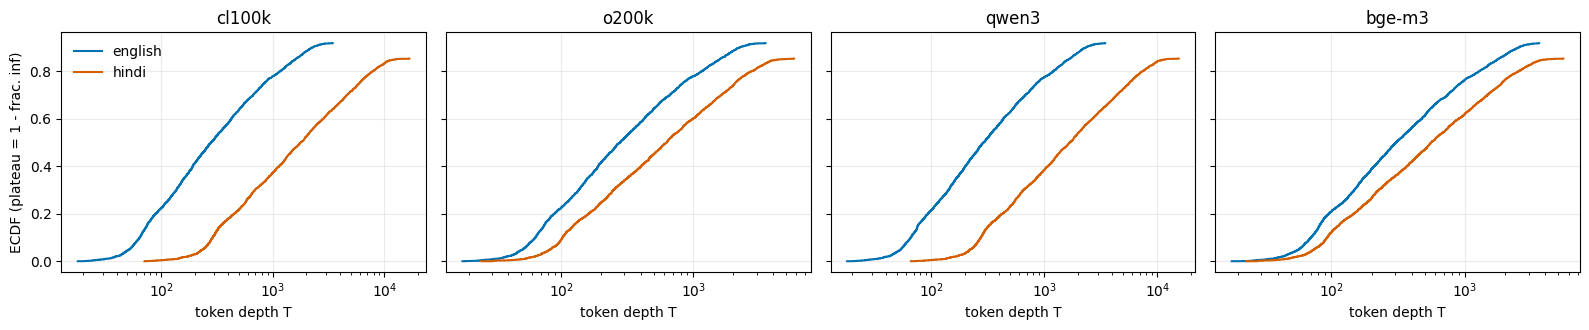

,lang,tokenizer,pct_inf,median_T
0,english,cl100k,8.2,281.0
1,hindi,cl100k,14.7,1783.0
2,english,o200k,8.2,279.0
3,hindi,o200k,14.7,625.0
4,english,qwen3,8.2,289.0
5,hindi,qwen3,14.7,1674.0
6,english,bge-m3,8.2,305.0
7,hindi,bge-m3,14.7,560.0


In [16]:
COL = {"english": "#0072B2", "hindi": "#D55E00", "russian": "#009E73", "arabic": "#CC79A7"}
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
drows = []
for ax, t in zip(axs, TOKS):
    for l in LANGS:
        T = E["T"][l][t]; x = np.sort(T[np.isfinite(T)])
        ax.step(x, np.arange(1, len(x) + 1) / len(T), where="post", color=COL.get(l, "grey"), label=l)
        drows.append({"lang": l, "tokenizer": t, "pct_inf": 100 * np.mean(~np.isfinite(T)), "median_T": np.median(T)})
    ax.set_xscale("log"); ax.set_title(t); ax.set_xlabel("token depth T"); ax.grid(alpha=.25)
axs[0].set_ylabel("ECDF (plateau = 1 - frac. inf)"); axs[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT / "depth_ecdf.png", dpi=150); plt.show()
DEPTH = pd.DataFrame(drows).round(1); display(DEPTH); DEPTH.to_csv(OUT / "eda_depth.csv", index=False)

### Implementation of the conformal procedure

Core functions, followed by unit tests on synthetic data (including the infeasible case), a feasibility guard, and the repeated-split experiment.

In [17]:
def need_k(n, alpha): return max(1, math.ceil(round((n + 1) * (1 - alpha), 9)))   # round() protects against float error, e.g. 20*0.95

def qh(s_sorted, alpha):               # s_sorted ascending
    n = len(s_sorted); k = need_k(n, alpha)
    return np.inf if k > n else s_sorted[k - 1]      # inf => retrieval-limited or too few items

def qhat(t_cal, alpha): return qh(np.sort(t_cal), alpha)

def cover(T, B):   # B = inf means "use all K_RET": coverage is then capped by recall
    return float(np.mean(np.isfinite(T) & (T <= B)))

def used(C, B):    # tokens actually sent: cumulative cost of the longest prefix within budget
    return float(np.where(C <= B, C, 0).max(1).mean())

def tau_of(s_cal, alpha):              # finite-sample corrected alpha-quantile (lower), for the score-threshold baseline
    k = int(math.floor(round(alpha * (len(s_cal) + 1), 9)))
    return -np.inf if k < 1 else np.sort(s_cal)[k - 1]

def make_splits(groups, R, seed):
    ug, inv = np.unique(groups, return_inverse=True); rng = np.random.default_rng(seed); out = []
    for _ in range(R):
        calg = np.zeros(len(ug), bool); calg[rng.permutation(len(ug))[: len(ug) // 2]] = True
        m = calg[inv]; out.append((np.where(m)[0], np.where(~m)[0]))
    return out

def cn(c, L): return c if L in ("english", "hindi") else f"{c}_{L}"   # Hindi is the primary test language: unsuffixed

In [18]:
# Unit tests on synthetic data
assert qhat(np.arange(1, 10.), 0.1) == 9                         # n=9: k=ceil(10*0.9)=9
assert qhat(np.arange(1, 20.), 0.05) == 19                       # n=19: k=ceil(20*0.95)=19 (float-safe)
assert np.isinf(qhat(np.arange(1, 10.), 0.05))                   # infeasible: k=ceil(9.5)=10 > n=9
assert np.isinf(qhat(np.array([1, 2, 3, np.inf, np.inf]), 0.2))  # retrieval-limited: 5th smallest is inf
assert qhat(np.array([5., 1, 3, 2, 4, 6, 7, 8, 9, 10]), 0.2) == 9   # unsorted input, n=10: k=ceil(8.8)=9
assert cover(np.array([1, 2, np.inf]), 2) == 2 / 3 and cover(np.array([1, 2, np.inf]), np.inf) == 2 / 3
Ct = np.array([[10, 20, 30], [5, 50, 60.]]); assert used(Ct, 25) == 12.5 and used(Ct, 4) == 0.0
assert tau_of(np.array([.1, .2, .3, .4, .5, .6, .7, .8, .9]), 0.2) == .2 and tau_of(np.array([.5, .6]), 0.05) == -np.inf
g_ = np.repeat(np.arange(40), 2); sp = make_splits(g_, 5, 0)
for cal_, te_ in sp:
    assert len(cal_) == len(te_) == 40 and not set(cal_) & set(te_) and not set(g_[cal_]) & set(g_[te_])   # grouped, disjoint, 50/50
assert all((a_[0] == b_[0]).all() and (a_[1] == b_[1]).all() for a_, b_ in zip(sp, make_splits(g_, 5, 0)))   # seeded
rs = np.random.default_rng(1); cv_ = []
for _ in range(2000):                                                # guarantee check on exchangeable data
    x = rs.lognormal(size=61); cv_.append(cover(x[1:], qhat(x[:30], 0.1)))
print("unit tests passed | iid coverage at alpha=0.1, n=30:", round(np.mean(cv_), 3), f"(window [0.900, {0.9 + 1 / 31:.3f}])")
print("infeasible case: qhat(n=9, alpha=0.05) =", qhat(np.arange(1, 10.), 0.05), "| ks_2samp with inf mass ok:",
      round(ks_2samp(np.array([1, 2, 1e18]), np.array([2, 3, 4.])).statistic, 3))

unit tests passed | iid coverage at alpha=0.1, n=30: 0.918 (window [0.900, 0.932])
infeasible case: qhat(n=9, alpha=0.05) = inf | ks_2samp with inf mass ok: 0.333


In [19]:
# Feasibility guard: calibration items per split and (n+1)(1-alpha) > n
SPL0 = make_splits(E["groups"], R, SEED); ncal = np.array([len(c) for c, _ in SPL0])
print(f"calibration items per split: min {ncal.min()} | median {int(np.median(ncal))} | max {ncal.max()}; test items per split: median {int(np.median([len(t) for _, t in SPL0]))}")
for a in ALPHAS:
    if need_k(ncal.min(), a) > ncal.min(): print(f"WARNING: alpha={a}: ceil((n+1)(1-alpha)) = {need_k(ncal.min(), a)} > n = {ncal.min()}: infeasible (B = inf) in some splits")
    for l in LANGS:
        sh = np.mean(~np.isfinite(E["T"][l][TOKS[0]]))
        if sh > a: print(f"WARNING: alpha={a}: {100*sh:.1f}% of {l} items have T = inf (> alpha): budgets are retrieval-limited (B = inf)")
for k in KS_FEW:
    if k > ncal.min(): print(f"note: few-label k={k} exceeds the smallest calibration half ({ncal.min()}); skipped in splits where k > n_cal")
    for a in ALPHAS:
        if k <= ncal.min() and need_k(k, a) > k: print(f"note: few-label k={k}, alpha={a}: ceil((k+1)(1-alpha)) = {need_k(k, a)} > k -> B = inf by construction")

calibration items per split: min 1499 | median 1500 | max 1500; test items per split: median 1499
note: few-label k=10, alpha=0.05: ceil((k+1)(1-alpha)) = 11 > k -> B = inf by construction


In [20]:
def run_splits(E, SPL, seed):
    REC, RATIO, BASE = {}, {}, {}
    def rec(cond, t, a, k, cov, B, u=np.nan):
        d = REC.setdefault((cond, t, a, k), {"cov": [], "B": [], "used": []}); d["cov"].append(cov); d["B"].append(B); d["used"].append(u)
    T, C, CO = E["T"], E["C"], E["cost"]; fh = E["first"]["hindi"]
    terc = {t: pd.qcut(pd.Series(E["qtokc"]["english"][t].values).rank(method="first"), 3, labels=False).values for t in TOKS}
    for r, (cal, te) in enumerate(SPL):
        rf = np.random.default_rng(seed + 1000 + r)
        for t in TOKS:
            Te, Th = T["english"][t], T["hindi"][t]
            for a in ALPHAS:
                Ben = qhat(Te[cal], a)
                rec("a", t, a, 0, cover(Te[te], Ben), Ben, used(C["english"][t][te], Ben))
                for L in TEST_LANGS:
                    TL, CL = T[L][t], C[L][t]; BL = qhat(TL[cal], a); Bd = Ben * E["kappa_by"][L][t]
                    rec(cn("b", L), t, a, 0, cover(TL[te], Ben), Ben, used(CL[te], Ben))
                    rec(cn("c", L), t, a, 0, cover(TL[te], BL), BL, used(CL[te], BL))
                    rec(cn("d", L), t, a, 0, cover(TL[te], Bd), Bd, used(CL[te], Bd))
                    if np.isfinite(Ben) and np.isfinite(BL): RATIO.setdefault((t, a, L), []).append(BL / Ben)
                    for tag, src in (("s_c", L), ("s_b", "english")):        # score-threshold baseline: B column holds tau (inf = keep all)
                        tau = tau_of(E["srel"][src][cal], a); keep = E["sc"][L][te] >= tau
                        rec(cn(tag, L), t, a, 0, float((E["hit"][L][te] & keep).any(1).mean()), np.inf if tau == -np.inf else float(tau),
                            float((keep * CO[L][t][te]).sum(1).mean()))
                Bf = qhat(np.concatenate([Te[cal], Th[cal]]), a)
                rec("f", t, a, 0, cover(Th[te], Bf), Bf, used(C["hindi"][t][te], Bf))
                for q in range(3):                                                  # descriptive: (b) by English query-length tercile
                    idx = te[terc[t][te] == q]
                    if len(idx): rec(f"b_terc{q}", t, a, 0, cover(Th[idx], Ben), Ben)
                for k in KS_FEW:
                    if k > len(cal): continue
                    sub = rf.choice(cal, k, replace=False); Bk = qhat(Th[sub], a)
                    rec("e", t, a, k, cover(Th[te], Bk), Bk)
            # baselines (Hindi test); conformal budget matched on *calibration* coverage
            Ch, Cth = C["hindi"][t], CO["hindi"][t]
            for k in TOPK_BASE:
                hitk = (fh >= 0) & (fh < k); Bm = qhat(Th[cal], 1 - hitk[cal].mean())
                BASE.setdefault(("topk", t, k), []).append((hitk[te].mean(), Ch[te, k - 1].mean(), cover(Th[te], Bm), used(Ch[te], Bm)))
            for F_ in FIXED_BUDGETS:
                Bm = qhat(Th[cal], 1 - cover(Th[cal], F_))
                BASE.setdefault(("fixedtok", t, F_), []).append((cover(Th[te], F_), used(Ch[te], F_), cover(Th[te], Bm), used(Ch[te], Bm)))
    return REC, RATIO, BASE

def lang_of(cond):
    for l in TEST_LANGS:
        if cond.endswith("_" + l): return l
    return "english" if cond == "a" else "hindi"

def base_cond(cond):
    for l in TEST_LANGS:
        if cond.endswith("_" + l): return cond[: -len(l) - 1]
    return cond

def summarize(E, REC, RATIO, BASE, seed):
    rows = []
    for (cond, t, a, k), v in REC.items():
        L, bc = lang_of(cond), base_cond(cond); cv, B = np.array(v["cov"]), np.array(v["B"]); fin = B[np.isfinite(B)]
        rows.append(dict(seed=seed, condition=cond, lang=L, tokenizer=t, alpha=a, k=k, n_splits=len(cv), cov_mean=cv.mean(), cov_p5=np.percentile(cv, 5),
                         cov_p95=np.percentile(cv, 95), gap=(1 - a) - cv.mean(), B_median=np.median(fin) if len(fin) else np.nan,
                         B_unit="cosine tau" if bc.startswith("s_") else "tokens", pct_inf=100 * np.mean(~np.isfinite(B)),
                         tokens_used=np.nanmean(v["used"]) if not np.all(np.isnan(v["used"])) else np.nan,
                         kappa=1.0 if L == "english" else E["kappa_by"][L][t],
                         ratio_Bhi_Ben=np.median(RATIO[(t, a, L)]) if bc == "c" and (t, a, L) in RATIO else np.nan,
                         infeasible=int(bc == "e" and need_k(k, a) > k)))
    for (kind, t, p), v in BASE.items():
        v = np.array(v)
        rows.append(dict(seed=seed, condition="base_" + kind, lang="hindi", tokenizer=t, k=p, n_splits=len(v), cov_mean=v[:, 0].mean(), cov_p5=np.percentile(v[:, 0], 5),
                         cov_p95=np.percentile(v[:, 0], 95), tokens_used=v[:, 1].mean(), cov_matched_conformal=v[:, 2].mean(), tokens_matched_conformal=v[:, 3].mean()))
    df = pd.DataFrame(rows); df["k"] = df["k"].astype("Int64")
    return df

In [21]:
# Bootstrap (paired group bootstrap over first-relevant-pid groups), shift statistics, window check, gate
def _members(groups):
    ug, inv = np.unique(groups, return_inverse=True)
    order = np.argsort(inv, kind="stable"); cuts = np.cumsum(np.bincount(inv))[:-1]
    return ug, inv, np.split(order, cuts)

def bootstrap(E, seed):
    ug, inv, members = _members(E["groups"]); rng = np.random.default_rng(seed + 7)
    keys = [(t, a, L) for t in TOKS for a in ALPHAS for L in TEST_LANGS]; acc = {k: {"gap_b": [], "gap_d": [], "ratio": []} for k in keys}
    for _ in range(N_BOOT):
        gs = rng.integers(0, len(ug), len(ug)); idx = np.concatenate([members[g] for g in gs]); lab = inv[idx]; ul = np.unique(gs)
        if len(ul) < 2: continue
        vals = {k: [] for k in keys}
        for _s in range(SPLITS_PER_BOOT):
            m = np.isin(lab, rng.permutation(ul)[: len(ul) // 2]); cal, te = idx[m], idx[~m]
            for t in TOKS:
                se = np.sort(E["T"]["english"][t][cal])
                for L in TEST_LANGS:
                    TL = E["T"][L][t]; sl = np.sort(TL[cal]); kap = E["kappa_by"][L][t]
                    for a in ALPHAS:
                        Ben, BL = qh(se, a), qh(sl, a)
                        vals[(t, a, L)].append(((1 - a) - cover(TL[te], Ben), (1 - a) - cover(TL[te], Ben * kap),
                                                BL / Ben if np.isfinite(Ben) and np.isfinite(BL) else np.nan))
        for k, v in vals.items():
            v = np.array(v); acc[k]["gap_b"].append(v[:, 0].mean()); acc[k]["gap_d"].append(v[:, 1].mean())
            acc[k]["ratio"].append(np.nanmean(v[:, 2]) if np.isfinite(v[:, 2]).any() else np.nan)
    return acc

def _ci(x): x = np.array(x, float); x = x[np.isfinite(x)]; return (np.percentile(x, 2.5), np.percentile(x, 97.5)) if len(x) else (np.nan, np.nan)

def shift_stats(E):
    rows = []
    for L in TEST_LANGS:
        for t in TOKS:
            x, y = E["T"]["english"][t], E["T"][L][t]; fx, fy = x[np.isfinite(x)], y[np.isfinite(y)]
            big = lambda z: np.where(np.isfinite(z), z, 1e18)
            ks_all = ks_2samp(big(x), big(y)).statistic            # includes the T = inf mass: this one bounds the coverage gap
            ks_fin = ks_2samp(fx, fy).statistic if len(fx) and len(fy) else np.nan
            edges = np.unique(np.quantile(np.concatenate([fx, fy]), np.linspace(0, 1, 51)))
            hx, hy = np.histogram(fx, edges)[0], np.histogram(fy, edges)[0]
            tv_fin = 0.5 * np.abs(hx / max(len(fx), 1) - hy / max(len(fy), 1)).sum()
            tv_all = 0.5 * np.abs(np.append(hx, (~np.isfinite(x)).sum()) / len(x) - np.append(hy, (~np.isfinite(y)).sum()) / len(y)).sum()
            rows.append(dict(condition="shift_stats", lang=L, tokenizer=t, ks_all=ks_all, ks_finite=ks_fin, tv_finite=tv_fin, tv_all=tv_all))
    return pd.DataFrame(rows)

def attach_extras(E, RES, BOOT, SPL):
    RES = RES.copy(); n = float(np.mean([len(c) for c, _ in SPL]))
    for c in ("gap_ci_lo", "gap_ci_hi", "ratio_ci_lo", "ratio_ci_hi", "win_lo", "win_hi", "in_window"): RES[c] = np.nan
    for i, r in RES.iterrows():
        if not isinstance(r.alpha, float) or np.isnan(r.alpha): continue
        bc, L = base_cond(r.condition), r.lang
        if bc in ("b", "d") and (r.tokenizer, r.alpha, L) in BOOT:
            RES.loc[i, ["gap_ci_lo", "gap_ci_hi"]] = _ci(BOOT[(r.tokenizer, r.alpha, L)]["gap_b" if bc == "b" else "gap_d"])
        if bc == "c" and (r.tokenizer, r.alpha, L) in BOOT: RES.loc[i, ["ratio_ci_lo", "ratio_ci_hi"]] = _ci(BOOT[(r.tokenizer, r.alpha, L)]["ratio"])
        if bc in ("a", "c"):
            lo, hi = 1 - r.alpha, 1 - r.alpha + 1 / (n + 1); RES.loc[i, ["win_lo", "win_hi"]] = (lo, hi); RES.loc[i, "in_window"] = float(lo <= r.cov_mean <= hi)
    return pd.concat([RES, shift_stats(E)], ignore_index=True)

def gate_from(RES, BOOT, alpha=GATE_ALPHA):
    g = RES[(RES.alpha == alpha) & (RES.lang == "hindi") & RES.condition.isin(["b", "d"])].pivot(index="tokenizer", columns="condition", values="gap").loc[list(TOKS)]
    out = pd.DataFrame({"gap_b": g["b"], "ci_lo": [_ci(BOOT[(t, alpha, "hindi")]["gap_b"])[0] for t in TOKS], "ci_hi": [_ci(BOOT[(t, alpha, "hindi")]["gap_b"])[1] for t in TOKS],
                        "gap_d": g["d"], "gap_d_lo": [_ci(BOOT[(t, alpha, "hindi")]["gap_d"])[0] for t in TOKS], "gap_d_hi": [_ci(BOOT[(t, alpha, "hindi")]["gap_d"])[1] for t in TOKS]})
    out["b_sig"] = (out.gap_b >= GAP_MIN) & (out.ci_lo > 0)
    out["d_closes"] = (out.gap_b >= GAP_MIN) & (out.gap_d.abs() <= NEAR)
    if out.b_sig.sum() >= 2: v = "PROCEED"
    elif out.d_closes.sum() >= 2: v = "PROCEED (method)"
    elif (out.gap_b.abs() <= NEAR).all(): v = "PIVOT"
    else: v = "CAUTION"
    return out, v

def analyze(E, seed):
    SPL = make_splits(E["groups"], R, seed)
    REC, RATIO, BASE = run_splits(E, SPL, seed); RES = summarize(E, REC, RATIO, BASE, seed)
    BOOT = bootstrap(E, seed); RES = attach_extras(E, RES, BOOT, SPL); GATE, V = gate_from(RES, BOOT)
    return dict(SPL=SPL, REC=REC, RATIO=RATIO, BASE=BASE, RES=RES, BOOT=BOOT, GATE=GATE, VERDICT=V)

In [22]:
A = analyze(E, SEED)                       # pre-committed analysis (SEED)
REC, RATIO, BASE, RES, BOOT, GATE, VERDICT = A["REC"], A["RATIO"], A["BASE"], A["RES"], A["BOOT"], A["GATE"], A["VERDICT"]
RES.to_csv(OUT / "results.csv", index=False)
print(f"{len(A['SPL'])} splits; {len(RES)} result rows -> {OUT.name}/results.csv")

200 splits; 216 result rows -> outputs/results.csv


## 5. Results

Tables are reported per $\alpha$ (target coverage $1-\alpha$). For each condition the table gives the mean test coverage over the splits and its 5th–95th percentile, the gap $(1-\alpha)-$coverage, the median budget $B$ (finite splits only; "n/a" if every split is infinite), the share of splits with $B=\infty$, the mean number of tokens sent, and $\kappa$. Condition codes: a EN→EN, b EN→HI, c HI→HI, d EN×κ→HI, e few-label HI, f pooled→HI, s_c / s_b score-threshold baseline calibrated on Hindi / English (its $B$ column is the cosine threshold $\tau$).

In [ ]:
def show(df): display(df.round(3).astype(object).where(df.notna(), "n/a").reset_index(drop=True))
cols = ["condition", "lang", "tokenizer", "alpha", "k", "cov_mean", "cov_p5", "cov_p95", "gap", "gap_ci_lo", "gap_ci_hi", "B_median", "ratio_Bhi_Ben", "ratio_ci_lo", "ratio_ci_hi", "kappa", "pct_inf", "tokens_used"]
MAIN = ["a", "b", "c", "d", "f", "s_c", "s_b"]
for a in ALPHAS:
    print(f"\n=== alpha = {a} (target coverage {1-a:.2f}) ===")
    show(RES[(RES.alpha == a) & RES.condition.map(base_cond).isin(MAIN)][cols].sort_values(["lang", "tokenizer", "condition"]))
print("\n=== (e) few-label Hindi calibration ==="); show(RES[RES.condition == "e"][cols + ["infeasible"]].sort_values(["alpha", "tokenizer", "k"]))
print("\n=== baselines (Hindi test; conformal budget matched on calibration coverage) ===")
show(RES[RES.condition.fillna("").str.startswith("base_")].dropna(axis=1, how="all").sort_values(["tokenizer", "condition", "k"]))

In [ ]:
print("=== within-language validity: mean coverage vs window [1-alpha, 1-alpha+1/(n_cal+1)] (n_cal = mean calibration size) ===")
V_ = RES[RES.condition.map(base_cond).isin(["a", "c"]) & (RES.lang.isin(["english", "hindi"]))][["condition", "tokenizer", "alpha", "cov_mean", "win_lo", "win_hi", "in_window", "pct_inf"]]
show(V_.sort_values(["condition", "alpha", "tokenizer"])); V_.to_csv(OUT / "validity_window.csv", index=False)
print("\n=== EN vs target-language depth distributions (finite = finite depths only; all = includes T=inf mass, bounds the coverage gap) ===")
show(RES[RES.condition == "shift_stats"][["lang", "tokenizer", "ks_all", "ks_finite", "tv_finite", "tv_all"]])
print("\n=== (b) coverage by English query-length tercile (descriptive; Hindi test, alpha=0.1) ===")
tb = RES[(RES.alpha == GATE_ALPHA) & RES.condition.str.startswith("b_terc")].pivot(index="tokenizer", columns="condition", values="cov_mean"); show(tb.reset_index())
print("\n=== share of splits with B = inf, by condition (alpha, tokenizer) ===")
Z = RES[RES.alpha.notna()].assign(cond=lambda d: d.condition + np.where(d.condition == "e", "_k" + d.k.astype(str), ""))
for a in ALPHAS: print(f"alpha={a}"); display(Z[Z.alpha == a].pivot_table(index="cond", columns="tokenizer", values="pct_inf").round(1).reindex(columns=list(TOKS)))

In [ ]:
CONDS = [("a", "a EN→EN", "#0072B2"), ("b", "b EN→HI", "#D55E00"), ("c", "c HI→HI", "#009E73"), ("d", "d EN×κ→HI", "#E69F00"), ("f", "f pooled→HI", "#CC79A7")]
TC = dict(zip(TOKS, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))

fig, axs = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for ax, t in zip(axs, TOKS):
    for ai, a in enumerate(ALPHAS):
        for ci, (c, lab, col) in enumerate(CONDS):
            bp = ax.boxplot(REC[(c, t, a, 0)]["cov"], positions=[ai * 6 + ci], widths=.7, patch_artist=True, showfliers=False, whis=(5, 95))
            for b in bp["boxes"]: b.set(facecolor=col, alpha=.8)
            for m in bp["medians"]: m.set(color="k")
        ax.hlines(1 - a, ai * 6 - .5, ai * 6 + 4.5, color="k", ls="--", lw=1)
    ax.set_xticks([ai * 6 + 2 for ai in range(3)]); ax.set_xticklabels([f"α={a}" for a in ALPHAS]); ax.set_title(t); ax.grid(axis="y", alpha=.25)
axs[0].set_ylabel("test coverage (box 25–75, whiskers 5–95)")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for _, _, c in CONDS], labels=[l for _, l, _ in CONDS], frameon=False, fontsize=9, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.savefig(OUT / "coverage_vs_alpha.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.8, 4.2))
for a, mk in zip(ALPHAS, "osD"):
    for c, col, fill in (("b", "#D55E00", True), ("d", "#009E73", False)):
        s = RES[(RES.condition == c) & (RES.alpha == a)].set_index("tokenizer").loc[list(TOKS)]
        g_ = {t: (1 - a) - np.array(REC[(c, t, a, 0)]["cov"]) for t in TOKS}
        lo = [s.gap[t] - np.percentile(g_[t], 5) for t in TOKS]; hi = [np.percentile(g_[t], 95) - s.gap[t] for t in TOKS]
        ax.errorbar(s.kappa, s.gap, yerr=[lo, hi], fmt=mk, mfc=col if fill else "none", color=col, ms=6, lw=1, label=f"{c}, α={a}")
for t in TOKS: ax.annotate(t, (E["kappa"][t], 0.99), xycoords=("data", "axes fraction"), rotation=90, va="top", ha="center", fontsize=7, color="grey")
ax.axhline(0, color="k", lw=.8); ax.axhline(GAP_MIN, color="grey", ls=":", lw=.8); ax.axhline(-NEAR, color="grey", ls=":", lw=.5); ax.axhline(NEAR, color="grey", ls=":", lw=.5)
ax.set_xlabel("measured premium κ (HI/EN cost)"); ax.set_ylabel("gap = (1-α) − coverage (bars: 5–95 over splits)")
ax.legend(frameon=False, fontsize=7); ax.grid(alpha=.25); plt.tight_layout(); plt.savefig(OUT / "gap_vs_premium.png", dpi=150); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8)); a = GATE_ALPHA
for t in TOKS:
    e = RES[(RES.condition == "e") & (RES.alpha == a) & (RES.tokenizer == t)].sort_values("k")
    if len(e):
        ks_x = e.k.astype(int); axs[0].plot(ks_x, e.cov_mean, "o-", color=TC[t], label=t); axs[0].fill_between(ks_x, e.cov_p5, e.cov_p95, color=TC[t], alpha=.15)
        axs[1].plot(ks_x, e.pct_inf, "o-", color=TC[t], label=t)
axs[0].axhline(1 - a, color="k", ls="--", lw=1); axs[0].set_xscale("log"); axs[0].set_xlabel("# Hindi calibration items k"); axs[0].set_ylabel(f"test coverage (α={a}; band 5–95)")
axs[1].set_xscale("log"); axs[1].set_xlabel("k"); axs[1].set_ylabel("% splits with B = inf")
for ax in axs: ax.grid(alpha=.25)
axs[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig(OUT / "label_efficiency.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.4, 4.2)); xs = [E["kappa"][t] for t in TOKS]; lim = [0.9 * min(xs), 1.1 * max(xs)]
ax.plot(lim, lim, "k--", lw=1, label="y = x")
for j, (a, mk) in enumerate(zip(ALPHAS, "osD")):
    s = RES[(RES.condition == "c") & (RES.alpha == a) & (RES.lang == "hindi")].set_index("tokenizer").loc[list(TOKS)]
    if s.ratio_Bhi_Ben.notna().any():
        ax.errorbar(s.kappa * (1 + 0.012 * (j - 1)), s.ratio_Bhi_Ben, yerr=[(s.ratio_Bhi_Ben - s.ratio_ci_lo).clip(lower=0), (s.ratio_ci_hi - s.ratio_Bhi_Ben).clip(lower=0)], fmt=mk, ms=6, lw=1, label=f"α={a}")
ax.set_xlabel("measured premium κ"); ax.set_ylabel("B_hi / B_en (median; bars: 95% bootstrap CI)"); ax.legend(frameon=False, fontsize=8); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig(OUT / "ratio_vs_kappa.png", dpi=150); plt.show()

## 6. Gate verdict and discussion

The gate uses the pre-committed thresholds (`GAP_MIN`, `NEAR`) at $\alpha=0.1$ and the primary seed `SEED`. The bootstrap resamples whole groups (first relevant passage id) with replacement, keeps English and Hindi items of the same query together, and averages the gap over 10 random 50/50 splits per replicate. Two robustness checks follow: the verdict for two other seeds, and the verdict when the relevant passages are **not** forced into the pool.

In [26]:
display(GATE.round(4)); GATE.to_csv(OUT / "gate.csv")
print("GATE VERDICT:", VERDICT, f"(gap = (1-alpha) - coverage; GAP_MIN={GAP_MIN}, NEAR={NEAR}; alpha={GATE_ALPHA}; seed={SEED})")
if EXTRA_LANGS:
    print("\n=== extra test languages: conditions b, c, d (alpha=0.1) ===")
    show(RES[(RES.alpha == GATE_ALPHA) & RES.lang.isin(EXTRA_LANGS) & RES.condition.map(base_cond).isin(["b", "c", "d"])][cols].sort_values(["lang", "condition", "tokenizer"]))

,gap_b,ci_lo,ci_hi,gap_d,gap_d_lo,gap_d_hi,b_sig,d_closes
tokenizer,,,,,,,,
cl100k,0.3424,0.2674,0.3699,0.0727,0.0559,0.0883,True,False
o200k,0.1322,0.1028,0.1535,0.0739,0.0568,0.0901,True,False
qwen3,0.3242,0.2532,0.3505,0.0734,0.0561,0.0892,True,False
bge-m3,0.0996,0.0788,0.1166,0.0720,0.0568,0.0890,True,False


GATE VERDICT: PROCEED (gap = (1-alpha) - coverage; GAP_MIN=0.05, NEAR=0.02; alpha=0.1; seed=0)


In [ ]:
# Robustness 1: three seeds (only the SEED verdict is the pre-committed one)
srows, A_SEEDS = [], {SEED: A}
for s in SEEDS:
    if s not in A_SEEDS: A_SEEDS[s] = analyze(E, s)
    g = A_SEEDS[s]["GATE"]
    srows.append({"seed": s, "pre-committed": s == SEED, "verdict": A_SEEDS[s]["VERDICT"], **{f"gap_b[{t}]": round(g.gap_b[t], 4) for t in TOKS},
                  **{f"gap_d[{t}]": round(g.gap_d[t], 4) for t in TOKS}, "n_b_sig": int(g.b_sig.sum()), "n_d_closes": int(g.d_closes.sum())})
SEEDTAB = pd.DataFrame(srows); display(SEEDTAB); SEEDTAB.to_csv(OUT / "gate_seeds.csv", index=False)

In [28]:
# Robustness 2: relevant passages forced into the pool (optimistic) vs BM25 top-100 only
def pool_rows(E_, A_, setting):
    rows = []
    for t in TOKS:
        g = A_["GATE"]; r = {"setting": setting, "tokenizer": t}
        for l in LANGS: r[f"recall@{K_RET}_{l}"] = (E_["first"][l] >= 0).mean(); r[f"pct_inf_{l}"] = 100 * np.mean(~np.isfinite(E_["T"][l][t]))
        r.update(gap_b=g.gap_b[t], ci_lo=g.ci_lo[t], ci_hi=g.ci_hi[t], gap_d=g.gap_d[t], verdict=A_["VERDICT"]); rows.append(r)
    return rows
NAME = {True: "relevant pids in pool (optimistic)", False: "BM25 top-100 only"}
prow = pool_rows(E, A, NAME[E["include_rel"]])
if RUN_NOREL_ROBUSTNESS:
    DS_ALT = {**make_ds(not INCLUDE_REL_IN_POOL), "qids": DS["qids"]}      # same queries, other pool setting
    E_ALT = get_E(DS_ALT, "dense"); A_ALT = analyze(E_ALT, SEED); prow += pool_rows(E_ALT, A_ALT, NAME[E_ALT["include_rel"]])
POOLTAB = pd.DataFrame(prow); show(POOLTAB.sort_values(["tokenizer", "setting"])); POOLTAB.to_csv(OUT / "pool_comparison.csv", index=False)

,setting,tokenizer,recall@30_english,pct_inf_english,recall@30_hindi,pct_inf_hindi,gap_b,ci_lo,ci_hi,gap_d,verdict
0,BM25 top-100 only,bge-m3,0.651,34.878,0.616,38.379,0.284,0.265,0.302,0.284,PROCEED
1,relevant pids in pool (optimistic),bge-m3,0.918,8.203,0.853,14.705,0.1,0.079,0.117,0.072,PROCEED
2,BM25 top-100 only,cl100k,0.651,34.878,0.616,38.379,0.284,0.265,0.302,0.284,PROCEED
3,relevant pids in pool (optimistic),cl100k,0.918,8.203,0.853,14.705,0.342,0.267,0.37,0.073,PROCEED
4,BM25 top-100 only,o200k,0.651,34.878,0.616,38.379,0.284,0.265,0.302,0.284,PROCEED
5,relevant pids in pool (optimistic),o200k,0.918,8.203,0.853,14.705,0.132,0.103,0.153,0.074,PROCEED
6,BM25 top-100 only,qwen3,0.651,34.878,0.616,38.379,0.284,0.265,0.302,0.284,PROCEED
7,relevant pids in pool (optimistic),qwen3,0.918,8.203,0.853,14.705,0.324,0.253,0.35,0.073,PROCEED


In [ ]:
# Optional: cross-encoder reranking of the top RERANK_TOP dense candidates (whole pipeline, separate files)
if USE_RERANKER:
    E_RR = get_E(DS, "rerank"); A_RR = analyze(E_RR, SEED)
    A_RR["RES"].to_csv(OUT / "results_reranked.csv", index=False); A_RR["GATE"].to_csv(OUT / "gate_reranked.csv")
    print({l: round(float((E_RR["first"][l] >= 0).mean()), 4) for l in LANGS}, "recall@K reranked | dense:", {l: round(float((E["first"][l] >= 0).mean()), 4) for l in LANGS})
    display(A_RR["GATE"].round(4)); print("GATE VERDICT (reranked):", A_RR["VERDICT"])
else: print("USE_RERANKER = False")

In [ ]:
def fm(x, f="{:.3f}"): return "n/a" if x is None or (isinstance(x, (float, np.floating)) and not np.isfinite(x)) else f.format(x)
def g1(c, t, a=GATE_ALPHA, L="hindi", col="cov_mean"): return RES[(RES.condition == cn(c, L)) & (RES.tokenizer == t) & (RES.alpha == a) & (RES.lang == L)].iloc[0][col]
r_ = lambda l: (E["first"][l] >= 0).mean()
print("=" * 78); print("SUMMARY")
print(f"1. N={len(E['qids'])} queries ({'QUICK' if QUICK else 'FULL'}, {'GPU' if CUDA else 'CPU'}); pool: {POOL_MODE.split(';')[0]}, include_rel={E['include_rel']}; K_RET={K_RET}; R={R} group splits; seed {SEED}.")
print(f"2. Retrieval: recall@{K_RET} EN {fm(r_('english'))} / HI {fm(r_('hindi'))}; MRR@10 EN {fm(RET.loc['MRR@10','english'])} / HI {fm(RET.loc['MRR@10','hindi'])}; BM25-only pool: " +
      (f"recall EN {fm((E_ALT['first']['english']>=0).mean())} / HI {fm((E_ALT['first']['hindi']>=0).mean())}." if RUN_NOREL_ROBUSTNESS else "not run."))
ks_ = RES[(RES.condition == "shift_stats") & (RES.lang == "hindi")].set_index("tokenizer")
print("3. kappa (HI/EN cost): " + ", ".join(f"{t} {E['kappa'][t]:.2f}" for t in TOKS) + "; KS(all) EN vs HI: " + ", ".join(f"{t} {fm(ks_.ks_all[t])}" for t in TOKS) + ".")
print("4. alpha=0.1 coverage (target 0.900) a EN->EN: " + ", ".join(f"{t} {fm(g1('a', t, L='english'))}" for t in TOKS) + " | c HI->HI: " + ", ".join(f"{t} {fm(g1('c', t))}" for t in TOKS) + " | b EN->HI: " + ", ".join(f"{t} {fm(g1('b', t))}" for t in TOKS) + ".")
print("5. (b) gap [95% boot CI]: " + "; ".join(f"{t} {GATE.gap_b[t]:+.3f} [{GATE.ci_lo[t]:+.3f},{GATE.ci_hi[t]:+.3f}]" for t in TOKS) + ".")
print("6. (d) rescaled gap [CI]: " + "; ".join(f"{t} {GATE.gap_d[t]:+.3f} [{GATE.gap_d_lo[t]:+.3f},{GATE.gap_d_hi[t]:+.3f}]" for t in TOKS) + ".")
print("7. B_hi/B_en vs kappa [CI]: " + "; ".join(f"{t} {fm(g1('c', t, col='ratio_Bhi_Ben'), '{:.2f}')} [{fm(g1('c', t, col='ratio_ci_lo'), '{:.2f}')},{fm(g1('c', t, col='ratio_ci_hi'), '{:.2f}')}] vs {E['kappa'][t]:.2f}" for t in TOKS) + ".")
e_ = RES[(RES.condition == "e") & (RES.alpha == GATE_ALPHA) & (RES.tokenizer == "o200k")].sort_values("k")
print("8. Few-label HI (o200k, alpha=0.1) cov by k: " + (", ".join(f"{int(r.k)}:{fm(r.cov_mean)}" + (f"(inf {r.pct_inf:.0f}%)" if r.pct_inf > 0 else "") for r in e_.itertuples()) or "n/a") +
      f" | score-threshold HI-cal cov {fm(g1('s_c', 'o200k'))} using {fm(g1('s_c', 'o200k', col='tokens_used'), '{:.0f}')} tokens vs budget (c) {fm(g1('c', 'o200k'))} using {fm(g1('c', 'o200k', col='tokens_used'), '{:.0f}')}.")
print(f"9. GATE: {VERDICT} (GAP_MIN={GAP_MIN}, NEAR={NEAR}); other seeds: " + ", ".join(f"{s}:{A_SEEDS[s]['VERDICT']}" for s in SEEDS if s != SEED) +
      (f"; BM25-only pool: {A_ALT['VERDICT']}" if RUN_NOREL_ROBUSTNESS else "") + "; % T=inf (HI, o200k) " + f"{DEPTH[(DEPTH.lang=='hindi')&(DEPTH.tokenizer=='o200k')].pct_inf.iloc[0]:.1f}%.")
print("10. Limits: passage-level relevance (not answer spans); machine-translated Hindi; identical candidate pids in both languages; relevant pids forced into pool" +
      (" (this run)" if E["include_rel"] else " (not in this run)") + "; one retriever; MS MARCO domain.")
print("=" * 78)

In [ ]:
# Auto-drafted discussion: every number below is read from the results of this run
a = GATE_ALPHA; N_ = len(E["qids"])
inf_ = lambda l: 100 * float(np.mean(~np.isfinite(E["T"][l][TOKS[0]])))
rng_ = lambda vals: (f"{min(vals):.3f}" if max(vals) - min(vals) < 5e-4 else f"{min(vals):.3f} to {max(vals):.3f}")
pool_desc = "the BM25 top-100 plus the relevant passages (the optimistic setting)" if E["include_rel"] else "the BM25 top-100 only"
S = []
S.append(f"The experiment used {N_} MS MARCO dev.small queries with candidate pools made of {pool_desc}, dense retrieval with BGE-M3 and K_RET = {K_RET}. "
         f"Recall@{K_RET} was {r_('english'):.3f} for English and {r_('hindi'):.3f} for Hindi, so the token depth is infinite for {inf_('english'):.1f}% of English and {inf_('hindi'):.1f}% of Hindi queries.")
lim = [f"alpha = {x}" for x in ALPHAS if max(inf_(l) for l in LANGS) / 100 > x]
S.append(("For " + ", ".join(lim) + ", more than a fraction alpha of items have infinite depth, so budgets are retrieval-limited there (B is infinite in most splits) and coverage is capped by recall.") if lim
         else "No alpha value is retrieval-limited: the share of infinite depths is below alpha for every alpha used.")
va = V_[V_.alpha == a]; nin = int(va.in_window.sum()); nall = len(va)
S.append(f"Within a language the conformal guarantee behaved as expected: at alpha = {a} the English-calibrated budget reached mean English coverage of {rng_([g1('a', t, L='english') for t in TOKS])} "
         f"and the Hindi-calibrated budget reached {rng_([g1('c', t) for t in TOKS])} on Hindi (target {1-a:.3f}); {nin} of {nall} within-language cases fall inside the theoretical window "
         f"[1-alpha, 1-alpha+1/(n+1)] at this alpha" + ("." if nin == nall else ", the others deviate (ties in the discrete depths and infinite budgets can move the mean outside the window)."))
S.append(f"Applying the English-calibrated budget to Hindi test queries (condition b) gave coverage " + ", ".join(f"{fm(g1('b', t))} ({t})" for t in TOKS) +
         f". The gap (1-alpha minus coverage) with its 95% group-bootstrap interval was " + "; ".join(f"{t} {GATE.gap_b[t]:+.3f} [{GATE.ci_lo[t]:+.3f}, {GATE.ci_hi[t]:+.3f}]" for t in TOKS) +
         f". The Kolmogorov-Smirnov distance between the English and Hindi depth distributions (including the infinite mass), which bounds the population gap between the two languages, was " + ", ".join(f"{fm(ks_.ks_all[t])} ({t})" for t in TOKS) + ".")
S.append("The measured token premium kappa (Hindi/English mean passage cost) was " + ", ".join(f"{E['kappa'][t]:.2f} ({t})" for t in TOKS) +
         ". The ratio of the Hindi-calibrated to the English-calibrated budget was " + ", ".join(f"{fm(g1('c', t, col='ratio_Bhi_Ben'), '{:.2f}')} [{fm(g1('c', t, col='ratio_ci_lo'), '{:.2f}')}, {fm(g1('c', t, col='ratio_ci_hi'), '{:.2f}')}] ({t})" for t in TOKS) +
         "; the interval contains kappa for " + str(sum(bool(g1('c', t, col='ratio_ci_lo') <= E['kappa'][t] <= g1('c', t, col='ratio_ci_hi')) for t in TOKS)) + f" of {len(TOKS)} tokenizers.")
S.append("Rescaling the English budget by kappa (condition d) gave gaps of " + "; ".join(f"{t} {GATE.gap_d[t]:+.3f} [{GATE.gap_d_lo[t]:+.3f}, {GATE.gap_d_hi[t]:+.3f}]" for t in TOKS) +
         f"; it lands within +/-{NEAR} of the target for {int((GATE.gap_d.abs() <= NEAR).sum())} of {len(TOKS)} tokenizers.")
S.append(f"The score-threshold baseline calibrated on Hindi reached coverage {rng_([g1('s_c', t) for t in TOKS])} using a mean of {fm(np.mean([g1('s_c', t, col='tokens_used') for t in TOKS]), '{:.0f}')} tokens, "
         f"against {rng_([g1('c', t) for t in TOKS])} with {fm(np.mean([g1('c', t, col='tokens_used') for t in TOKS]), '{:.0f}')} tokens for the Hindi-calibrated budget (averaged over tokenizers; condition s_b, calibrated on English, reached {rng_([g1('s_b', t) for t in TOKS])}).")
S.append("Verdict by seed: " + ", ".join(f"seed {s}{' (pre-committed)' if s == SEED else ''}: {A_SEEDS[s]['VERDICT']}" for s in SEEDS) +
         ((f"; with the other pool setting (" + NAME[E_ALT['include_rel']] + f") it was {A_ALT['VERDICT']}.") if RUN_NOREL_ROBUSTNESS else "."))
S.append({"PROCEED": f"Gate verdict: PROCEED. The pre-committed criterion is met: the English-calibrated budget under-covers Hindi by at least {GAP_MIN} with a bootstrap interval excluding zero for {int(GATE.b_sig.sum())} tokenizers, so the exchangeability assumption fails in a way that matters in practice.",
          "PROCEED (method)": f"Gate verdict: PROCEED (method). The English-calibrated budget misses the target by at least {GAP_MIN} for {int((GATE.gap_b >= GAP_MIN).sum())} tokenizers without the interval criterion being met for two, but premium rescaling brings coverage within {NEAR} of the target for {int(GATE.d_closes.sum())} tokenizers.",
          "PIVOT": f"Gate verdict: PIVOT. The gap is within +/-{NEAR} for all tokenizers: in this setup the English-calibrated budget transfers to Hindi without a measurable loss of coverage. This is a null result for the shift hypothesis and is reported as such.",
          "CAUTION": f"Gate verdict: CAUTION. Neither the PROCEED criteria nor the PIVOT criterion is met unambiguously (gaps: " + ", ".join(f"{t} {GATE.gap_b[t]:+.3f}" for t in TOKS) + "); the evidence is mixed and should not be read as either a confirmed shift or a confirmed absence of shift."}[VERDICT])
import textwrap
print("\n\n".join(textwrap.fill(s, 120) for s in S))

## 7. Limitations

- **Passage-level relevance.** Relevance labels mark whole passages, not answer spans; a passage can be labelled relevant without containing the answer, and unlabelled passages may also be relevant (sparse MS MARCO labels). The depth $T$ is the cost of reaching the first *labelled* passage, not the cost of reaching an answer.
- **Machine-translated Hindi.** mMARCO Hindi is machine translated. Token counts, retrieval quality and the premium $\kappa$ may differ for natural Hindi text and queries.
- **Identical candidate pids.** The candidate pool comes from an English BM25 run and is used unchanged in both languages. A Hindi first-stage retriever would produce different pools.
- **Relevant passages forced into the pool.** With `INCLUDE_REL_IN_POOL=True` the relevant passage is always a candidate. This is optimistic and removes first-stage misses; the BM25-only comparison above quantifies the difference.
- **Single retriever.** One dense retriever (BGE-M3) is used, with an optional reranker; other retrievers may shift the two depth distributions differently.
- **Domain.** All results are for MS MARCO web-search passages; other domains and longer documents are not covered.
- **Exchangeability at group level.** Splits are grouped by the first relevant passage id. Queries sharing a passage are therefore never split across calibration and test, but other dependencies between queries are not modelled.
- **Statistical scope.** Coverage is averaged over repeated random splits of one finite sample; the bootstrap interval reflects sampling variability of the query set, not variation across retrievers, languages or domains.

## 8. Conclusion and future work

*[To be written from the printed summary and the auto-drafted discussion above. State the verdict exactly as printed. If the verdict is PIVOT or CAUTION, report the absence of a detected shift or the ambiguity plainly; a null result is a valid finding.]*

Future work: replace machine-translated queries with native Hindi queries; use language-specific first-stage retrievers; calibrate on answer-span relevance; test additional languages (`EXTRA_LANGS`) and retrievers/rerankers (`USE_RERANKER`); study conformal methods that are robust to covariate shift (for example, weighted conformal prediction with the premium as the shift variable).

In [ ]:
# Optional (OFF): MLQA en-hi replication with the context paragraph as evidence
if RUN_MLQA:
    zp = DATA / "MLQA_V1.zip"
    if not zp.exists():
        with requests.get("https://dl.fbaipublicfiles.com/MLQA/MLQA_V1.zip", stream=True, timeout=60) as r, open(zp, "wb") as f:
            for c in r.iter_content(1 << 20): f.write(c)
    def load(split, ctx, qs):
        with zipfile.ZipFile(zp) as z: d = json.load(z.open(f"MLQA_V1/{split}/{split}-context-{ctx}-question-{qs}.json"))["data"]
        return [(p["context"], qa["id"], qa["question"]) for a_ in d for p in a_["paragraphs"] for qa in p["qas"]]
    en, hi = [], []
    for sp in ("dev", "test"): en += load(sp, "en", "en"); hi += load(sp, "hi", "hi")
    hid = {i: (c, q) for c, i, q in hi}; en = [x for x in en if x[1] in hid]           # align by id
    key = {}
    for c, i, q in en: key.setdefault(c, i)
    pid_of = {k: n for n, k in enumerate(dict.fromkeys(key.values()))}
    ptext = {"english": {}, "hindi": {}}; qtext = {"english": {}, "hindi": {}}; rel = {}; qids = []
    for n, (c, i, q) in enumerate(en):
        p = pid_of[key[c]]; ptext["english"][p] = c; ptext["hindi"].setdefault(p, hid[i][0])
        qtext["english"][n] = q; qtext["hindi"][n] = hid[i][1]; rel[n] = [p]; qids.append(n)
    allp = list(ptext["english"]); ML = dict(tag="mlqa", langs=("english", "hindi"), include_rel=True, qids=qids, pools={q: allp for q in qids}, rel=rel, qtext=qtext, ptext=ptext)
    EM = build_E(ML)                                                                    # pool = all paragraphs (single-hop corpus)
    AM = analyze(EM, SEED); AM["RES"].to_csv(OUT / "results_mlqa.csv", index=False); display(AM["GATE"].round(4)); print("MLQA gate:", AM["VERDICT"])
else:
    print("RUN_MLQA = False")

In [ ]:
# Zip all outputs (results.csv, gate.csv, PNGs, tables) into ./outputs.zip
zpath = shutil.make_archive(str(ROOT / ("outputs_synth" if SYNTHETIC_TEST else "outputs")), "zip", OUT)
print("outputs archive:", zpath); print(sorted(p.name for p in OUT.iterdir()))

In [ ]:
# EXTRA 1 (exploratory, found after seeing results): rank-depth decomposition  B_L/B_en  ~  kappa * rho
# rho = ratio of the same conformal quantile of RANK depth (passages needed to reach the gold one), no tokenizer involved.
SPL = A["SPL"]; ALPHAS_X = (0.2, 0.25, 0.3, 0.4)        # alphas where the Hindi budget is finite (infinite mass < alpha)
def rank_depth(L):
    f = E["first"][L]; return np.where(f >= 0, f + 1.0, np.inf)
rows = []
for L in TEST_LANGS:
    De, Dl = rank_depth("english"), rank_depth(L)
    for t in TOKS:
        Te, Tl = E["T"]["english"][t], E["T"][L][t]; kap = E["kappa_by"][L][t]
        for a in ALPHAS_X:
            rho, obs = [], []
            for cal, te in SPL:
                Ke, Kl = qh(np.sort(De[cal]), a), qh(np.sort(Dl[cal]), a)
                Be, Bl = qh(np.sort(Te[cal]), a), qh(np.sort(Tl[cal]), a)
                if np.isfinite([Ke, Kl, Be, Bl]).all(): rho.append(Kl / Ke); obs.append(Bl / Be)
            if len(obs) < 20: continue
            rho, obs = np.array(rho), np.array(obs); ratio = obs / (kap * rho)
            rows.append(dict(lang=L, tokenizer=t, alpha=a, kappa=kap, rho_rank=np.median(rho), kappa_x_rho=kap * np.median(rho),
                             B_ratio_observed=np.median(obs), obs_over_kappa=np.median(obs) / kap,
                             obs_over_kappa_rho=np.median(ratio), p5=np.percentile(ratio, 5), p95=np.percentile(ratio, 95), n_splits=len(obs)))
DEC = pd.DataFrame(rows); DEC.to_csv(OUT / "decomposition.csv", index=False); display(DEC.round(3))
print("Reading: obs_over_kappa = excess over the token premium; obs_over_kappa_rho ~ 1 means kappa x rho explains the budget ratio; "
      "rho ~ 1 would mean rank displacement is NOT the cause. Spread p5-p95 is over splits, not a group bootstrap. Exploratory.")

In [35]:
# EXTRA 2: coverage CONDITIONAL on the answer being retrieved (T finite). Calibrate and test on items with T < inf only.
# This is the "coverage on feasible items" guarantee, so budgets stay finite at alpha = 0.05 / 0.1. Unconditional coverage = this x P(retrieved).
rows = []
for L in TEST_LANGS:
    De, Dl = rank_depth("english"), rank_depth(L)
    for t in TOKS:
        Te, Tl = E["T"]["english"][t], E["T"][L][t]; kap = E["kappa_by"][L][t]; fe, fl = np.isfinite(Te), np.isfinite(Tl)
        for a in ALPHAS:
            acc = {k: [] for k in ("a", "b", "c", "d", "d_rho")}; Bs = {"en": [], "tl": []}
            for cal, te in SPL:
                ce, cl, te_e, te_l = cal[fe[cal]], cal[fl[cal]], te[fe[te]], te[fl[te]]
                Be, Bl = qh(np.sort(Te[ce]), a), qh(np.sort(Tl[cl]), a)
                rho = qh(np.sort(Dl[cl]), a) / qh(np.sort(De[ce]), a)          # needs L labels: diagnostic, not label-free
                acc["a"].append(cover(Te[te_e], Be)); acc["b"].append(cover(Tl[te_l], Be)); acc["c"].append(cover(Tl[te_l], Bl))
                acc["d"].append(cover(Tl[te_l], Be * kap)); acc["d_rho"].append(cover(Tl[te_l], Be * kap * rho))
                Bs["en"].append(Be); Bs["tl"].append(Bl)
            for k, v in acc.items():
                v = np.array(v); rows.append(dict(lang=L, tokenizer=t, alpha=a, condition=k + "_cond", target=1 - a, cov_mean=v.mean(),
                                                  cov_p5=np.percentile(v, 5), cov_p95=np.percentile(v, 95), gap=(1 - a) - v.mean(),
                                                  P_retrieved_en=fe.mean(), P_retrieved_L=fl.mean(),
                                                  B_ratio_cond=np.median(np.array(Bs["tl"]) / np.array(Bs["en"])), kappa=kap))
CC = pd.DataFrame(rows); CC.to_csv(OUT / "conditional_coverage.csv", index=False)
display(CC[CC.alpha == GATE_ALPHA].round(3))
print("a_cond = EN->EN, b_cond = EN->L, c_cond = L->L, d_cond = English budget x kappa, d_rho_cond = x kappa x rho (uses L labels). "
      "Valid within a language because conditioning on T < inf keeps calibration and test items exchangeable.")

,lang,tokenizer,alpha,condition,target,cov_mean,cov_p5,cov_p95,gap,P_retrieved_en,P_retrieved_L,B_ratio_cond,kappa
5,hindi,cl100k,0.1,a_cond,0.9,0.900,0.883,0.920,0.000,0.918,0.853,4.757,4.208
6,hindi,cl100k,0.1,b_cond,0.9,0.521,0.498,0.542,0.379,0.918,0.853,4.757,4.208
7,hindi,cl100k,0.1,c_cond,0.9,0.900,0.881,0.918,-0.000,0.918,0.853,4.757,4.208
8,hindi,cl100k,0.1,d_cond,0.9,0.870,0.851,0.889,0.030,0.918,0.853,4.757,4.208
9,hindi,cl100k,0.1,d_rho_cond,0.9,0.897,0.875,0.917,0.003,0.918,0.853,4.757,4.208
20,hindi,o200k,0.1,a_cond,0.9,0.900,0.883,0.920,-0.000,0.918,0.853,1.655,1.488
21,hindi,o200k,0.1,b_cond,0.9,0.777,0.755,0.798,0.123,0.918,0.853,1.655,1.488
22,hindi,o200k,0.1,c_cond,0.9,0.900,0.881,0.919,-0.000,0.918,0.853,1.655,1.488
23,hindi,o200k,0.1,d_cond,0.9,0.871,0.851,0.892,0.029,0.918,0.853,1.655,1.488
24,hindi,o200k,0.1,d_rho_cond,0.9,0.901,0.876,0.919,-0.001,0.918,0.853,1.655,1.488


a_cond = EN->EN, b_cond = EN->L, c_cond = L->L, d_cond = English budget x kappa, d_rho_cond = x kappa x rho (uses L labels). Valid within a language because conditioning on T < inf keeps calibration and test items exchangeable.
